# Reto 1 · Exploración y calidad de datos

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Objetivo: entender la base de clientes y **auditar la calidad del dato** antes de segmentar. Cada decisión de
limpieza se toma con datos, comparando alternativas y midiendo su efecto, porque una mala decisión aquí se
arrastra a los clusters.

1. Carga, tipos y **granularidad** (¿qué es una fila?)
2. Exclusión justificada de **metadatos e identificadores**
3. **Valores nulos**: cuánto falta, **por qué** falta (mecanismo) y **qué hacer** en cada columna
4. **Inconsistencias** y detalles del dato
5. **Estadísticas descriptivas** y **distribuciones**, separando por país y por nivel (cliente / vehículo)
6. **Relaciones no evidentes**: dentro del CSV, con datos oficiales de seguridad vial y con datos oficiales de salud
   (ergonomía)
7. Resumen de hallazgos y conclusiones

**Dos niveles de análisis.** El fichero tiene una fila por **relación cliente–vehículo**. Los atributos de cliente
(edad, consentimientos, código postal…) se repiten en cada vehículo del cliente. Por eso, todo lo que describe
**clientes** se calcula con **una fila por cliente** (si no, los clientes con muchos vehículos pesarían más), y lo
que describe **vehículos** con todas las filas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
AZUL, AZUL_CLARO = "#00677F", "#9cc3cc"

DATA = "datos_reto_mercedes_benz_malackathon.csv"  # CSV en la raíz del repositorio
# zipcode se lee como texto: mezcla números y textos (p. ej. "CH-6340") y no es una cantidad
df = pd.read_csv(DATA, dtype={"zipcode": "string"}, low_memory=False)
df.shape

(302850, 39)

## 1. Estructura y granularidad

In [2]:
df.head(3).T

,0,1,2
Unnamed: 0,0,1,2
client_id,000144e39c02702f821f69beeb7036f40cf8505051050f...,000144e39c02702f821f69beeb7036f40cf8505051050f...,0002f3a9f4483f444b7665eba96822dad2f1dcfe8d0fab...
vehicle_id,db75a50f450de43f5f7a94d2a05b605fdc1a5d84913ba6...,e1ddd663e780ffc6dc8194aeb1189a2176ca796d5d3897...,716e4f639ce69defa3b9ce202848cdca612814e7d0dc47...
age_range,35-44,35-44,25-34
gender_derived,female,female,male
model_series,177,206,213
vehicle_type,A 180 d,C 200 d,AMG E 63 S 4MATIC+
model_class,A-Class,C-Class,E-Class
product_group,P,P,P
engine_concept,NaN,NaN,COMBUSTION


In [3]:
tipos = pd.DataFrame({"tipo": df.dtypes.astype(str), "valores distintos": df.nunique(),
                      "% nulos": df.isna().mean().mul(100).round(1), "ejemplo": df.iloc[1]})
tipos

,tipo,valores distintos,% nulos,ejemplo
Unnamed: 0,int64,302850,0.00,1
client_id,str,173456,0.00,000144e39c02702f821f69beeb7036f40cf8505051050f...
vehicle_id,str,244519,0.00,e1ddd663e780ffc6dc8194aeb1189a2176ca796d5d3897...
age_range,str,6,0.00,35-44
gender_derived,str,2,11.20,female
model_series,int64,88,0.00,206
vehicle_type,str,1436,0.30,C 200 d
model_class,str,42,1.10,C-Class
product_group,str,4,0.00,P
engine_concept,str,4,44.40,NaN


Ajustes de tipo necesarios: `date_of_first_registration` llega como texto (se convierte a fecha);
`trip_distance_mode` y `speed_mode` llegan como texto porque a veces contienen **varios valores separados por
comas** (modas empatadas); `model_series` es un código y no una cantidad.

In [4]:
n_rows, n_clients, n_vehicles = len(df), df["client_id"].nunique(), df["vehicle_id"].nunique()
pd.Series({
    "filas (relaciones cliente-vehículo)": n_rows,
    "clientes únicos": n_clients,
    "vehículos únicos": n_vehicles,
    "pares (cliente, vehículo) duplicados": df.duplicated(["client_id", "vehicle_id"]).sum(),
    "filas duplicadas completas (sin el índice)": df.drop(columns="Unnamed: 0").duplicated().sum(),
    "¿'Unnamed: 0' es 0..n-1?": int((df["Unnamed: 0"].to_numpy() == np.arange(n_rows)).all()),
})

filas (relaciones cliente-vehículo)           302850
clientes únicos                               173456
vehículos únicos                              244519
pares (cliente, vehículo) duplicados               0
filas duplicadas completas (sin el índice)         0
¿'Unnamed: 0' es 0..n-1?                           1
dtype: int64

No hay duplicados. Hay **más relaciones que vehículos**: un mismo vehículo puede estar vinculado a varios
clientes (propietario, conductor, usuario temporal…).

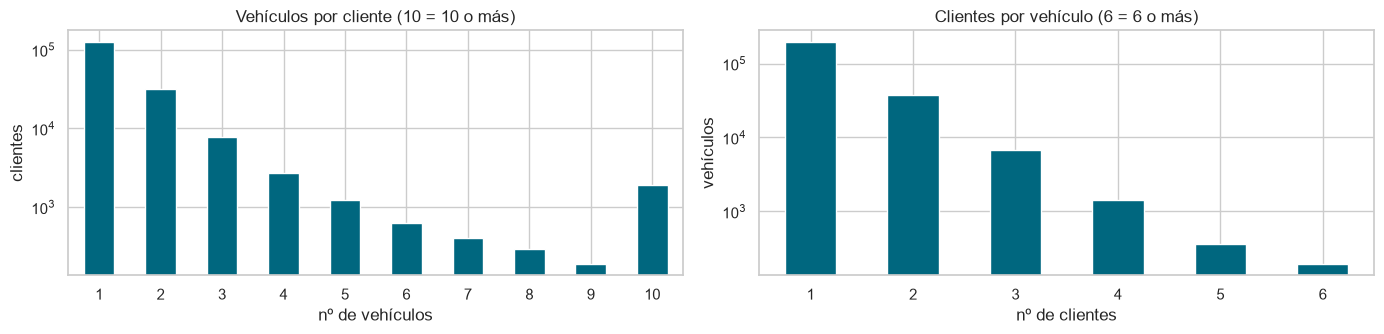

mediana de vehículos por cliente                 1.00
clientes con >10 vehículos (perfil flota)    1,706.00
  % de clientes                                  1.00
  % de filas que acumulan                       20.00
  máximo de vehículos de un cliente            561.00
vehículos vinculados a >1 cliente           46,648.00
  máximo de clientes de un vehículo             36.00
dtype: float64

In [5]:
veh_por_cliente = df.groupby("client_id").size()
cli_por_veh = df.groupby("vehicle_id")["client_id"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
veh_por_cliente.clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[0], color=AZUL, rot=0)
axes[0].set(title="Vehículos por cliente (10 = 10 o más)", xlabel="nº de vehículos", ylabel="clientes", yscale="log")
cli_por_veh.clip(upper=6).value_counts().sort_index().plot.bar(ax=axes[1], color=AZUL, rot=0)
axes[1].set(title="Clientes por vehículo (6 = 6 o más)", xlabel="nº de clientes", ylabel="vehículos", yscale="log")
plt.tight_layout()
plt.show()

grandes = veh_por_cliente[veh_por_cliente > 10]
compartidos = cli_por_veh[cli_por_veh > 1]
pd.Series({
    "mediana de vehículos por cliente": veh_por_cliente.median(),
    "clientes con >10 vehículos (perfil flota)": len(grandes),
    "  % de clientes": len(grandes) / n_clients * 100,
    "  % de filas que acumulan": grandes.sum() / n_rows * 100,
    "  máximo de vehículos de un cliente": veh_por_cliente.max(),
    "vehículos vinculados a >1 cliente": len(compartidos),
    "  máximo de clientes de un vehículo": cli_por_veh.max(),
}).round(1)

In [6]:
# ¿Qué atributos son de cliente, de vehículo o de la relación? Se comprueba si son constantes dentro de cada grupo
atrib_cliente = ["age_range", "gender_derived", "country_code", "months_as_mb_customer", "currently_connected_vehicles",
                 "finance_leasing_status", "consent_phone_communication_channel", "consent_epost_communication_channel",
                 "consent_post_communication_channel", "zipcode", "purchasing_power_per_household_eur"]
atrib_vehiculo = ["model_class", "vehicle_type", "engine_concept", "fuel_type", "date_of_first_registration",
                  "trip_distance_average", "speed_average", "workshop_visits_warranty_goodwill"]
var_cli = (df.groupby("client_id")[atrib_cliente].nunique(dropna=False) > 1).sum()
var_veh = (df[df["vehicle_id"].isin(compartidos.index)].groupby("vehicle_id")[atrib_vehiculo].nunique(dropna=False) > 1).sum()
display(var_cli.rename("clientes con >1 valor").to_frame())
var_veh.rename("vehículos compartidos con >1 valor").to_frame()

,clientes con >1 valor
age_range,0
gender_derived,0
country_code,0
months_as_mb_customer,0
currently_connected_vehicles,0
finance_leasing_status,0
consent_phone_communication_channel,0
consent_epost_communication_channel,0
consent_post_communication_channel,0
zipcode,0


,vehículos compartidos con >1 valor
model_class,0
vehicle_type,0
engine_concept,0
fuel_type,0
date_of_first_registration,0
trip_distance_average,24993
speed_average,24883
workshop_visits_warranty_goodwill,29292


- Los **atributos de cliente** son 100 % constantes entre sus filas: la agregación a una fila por cliente no tiene
  conflictos.
- Los atributos técnicos del vehículo (modelo, motor, matriculación) coinciden entre los clientes que lo comparten.
  En cambio, la **telemetría** y las **visitas al taller** cambian: son datos de la **relación** (cómo conduce *ese*
  cliente *ese* coche), no del vehículo. Por eso se agregarán por cliente y no por vehículo.

In [7]:
# Roles: qué significa cada uno y si la relación sigue activa
roles = pd.crosstab(df["role"], df["is_current_vehicle"], margins=True)
roles["% activa"] = roles[True] / roles["All"] * 100
roles

is_current_vehicle,False,True,All,% activa
role,,,,
DRIVER,4972,549,5521,9.94
LEGACY,6094,5220,11314,46.14
OWNER,102782,161636,264418,61.13
TEMP_USER,3795,171,3966,4.31
USER,5041,12590,17631,71.41
All,122684,180166,302850,59.49


## 2. Columnas de metadatos e identificadores

| Columna | Decisión | Motivo |
|---|---|---|
| `Unnamed: 0` | **Excluir** | Índice exportado (es exactamente 0…n-1); no es información |
| `client_id` | **Excluir como feature** | Hash identificador. Solo como clave para agregar por cliente |
| `vehicle_id` | **Excluir** | Hash identificador. Solo para contar vehículos |
| `zipcode` | **Excluir como feature** | Identificador geográfico (4.610 valores); su información útil está en las variables socioeconómicas del CP |
| `model_series` | **Excluir** | Código interno; `model_class` resume la misma información de forma legible |
| `vehicle_type` | **Excluir como feature** | 1.436 denominaciones comerciales; se usa solo para **deducir** gama y electrificación cuando faltan |
| `trip_distance_mode`, `speed_mode` | **Excluir** | Texto con modas empatadas ("3,7.5") y valores de tramo de histograma (ver apartado 4) |
| `trip_distance_median`, `speed_median` | **Excluir** | Solo 12-13 valores posibles: son **límites de tramo**, no medianas reales |
| `trip_distance_all_counter`, `speed_all_counter` | **Excluir como feature** | Contadores técnicos de mediciones, no comportamiento del cliente |
| `fuel_type` | **Excluir** | Redundante con `engine_concept` y con más nulos (59 % vs 44 %) |

## 3. Valores nulos

### 3.1 ¿Cuánto falta?

El porcentaje de nulos cambia según el nivel. A nivel **cliente**, un atributo de vehículo cuenta como nulo solo
si falta en **todos** sus vehículos.

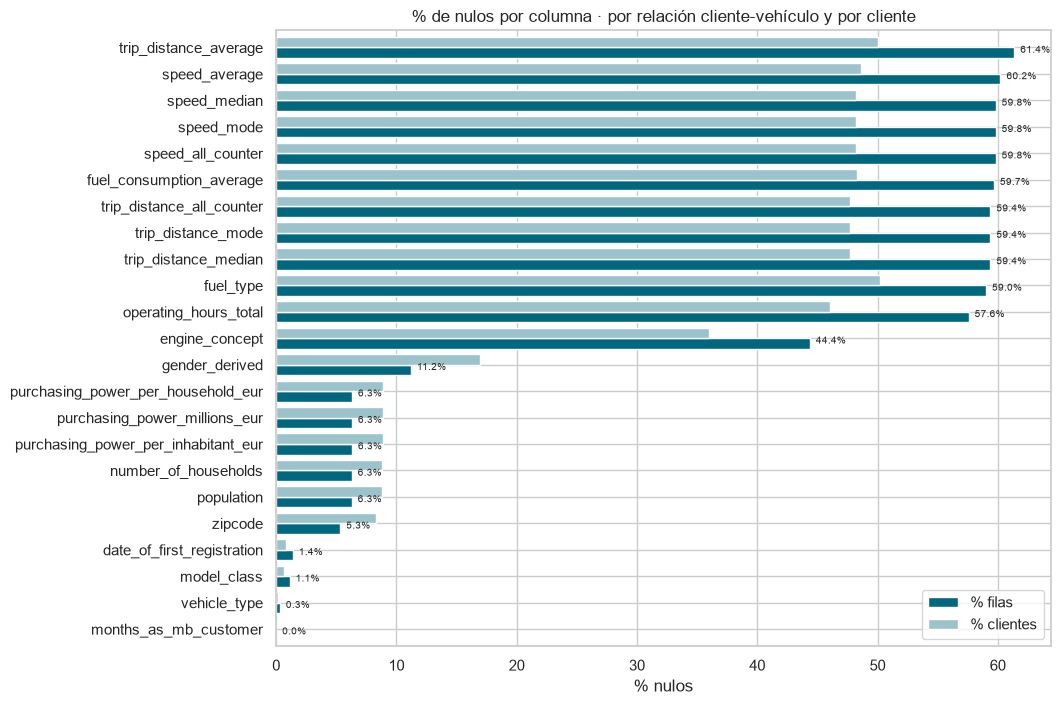

,% filas,% clientes
trip_distance_average,61.40,50.10
speed_average,60.20,48.60
speed_median,59.80,48.20
speed_all_counter,59.80,48.20
speed_mode,59.80,48.20
fuel_consumption_average,59.70,48.30
trip_distance_median,59.40,47.70
trip_distance_all_counter,59.40,47.70
trip_distance_mode,59.40,47.70
fuel_type,59.00,50.20


In [8]:
nul_filas = df.isna().mean().mul(100)
nul_cli = df.isna().groupby(df["client_id"]).all().mean().mul(100)
nulos = pd.DataFrame({"% filas": nul_filas, "% clientes": nul_cli})
nulos = nulos[nulos["% filas"] > 0].sort_values("% filas")
ax = nulos.plot.barh(figsize=(10, 8), color=[AZUL, AZUL_CLARO], width=.8)
for i, v in enumerate(nulos["% filas"]):
    ax.text(v + .5, i - .2, f"{v:.1f}%", fontsize=7)
ax.set(title="% de nulos por columna · por relación cliente-vehículo y por cliente", xlabel="% nulos")
plt.show()
nulos.sort_values("% filas", ascending=False).round(1)

Hay **tres bloques** de columnas con nulos: telemetría (~60 % de filas), motorización (44-59 %) y
socioeconómicos (6 %). Fuera de ellos, solo `gender_derived` (11 % de filas, 17 % de clientes) y nulos residuales
(< 1,5 %). El nivel importa: los socioeconómicos faltan en el 6,3 % de las filas pero en el **8,9 % de los
clientes**, porque los clientes sin dato tienen, de media, menos vehículos. Medir solo por filas subestimaría el problema.

### 3.2 ¿Los nulos van juntos?

Mapa de presencia (azul = nulo) sobre una muestra y correlación entre los indicadores de nulo. Columnas cuyo nulo
está muy correlacionado faltan **a la vez**, por una misma causa.

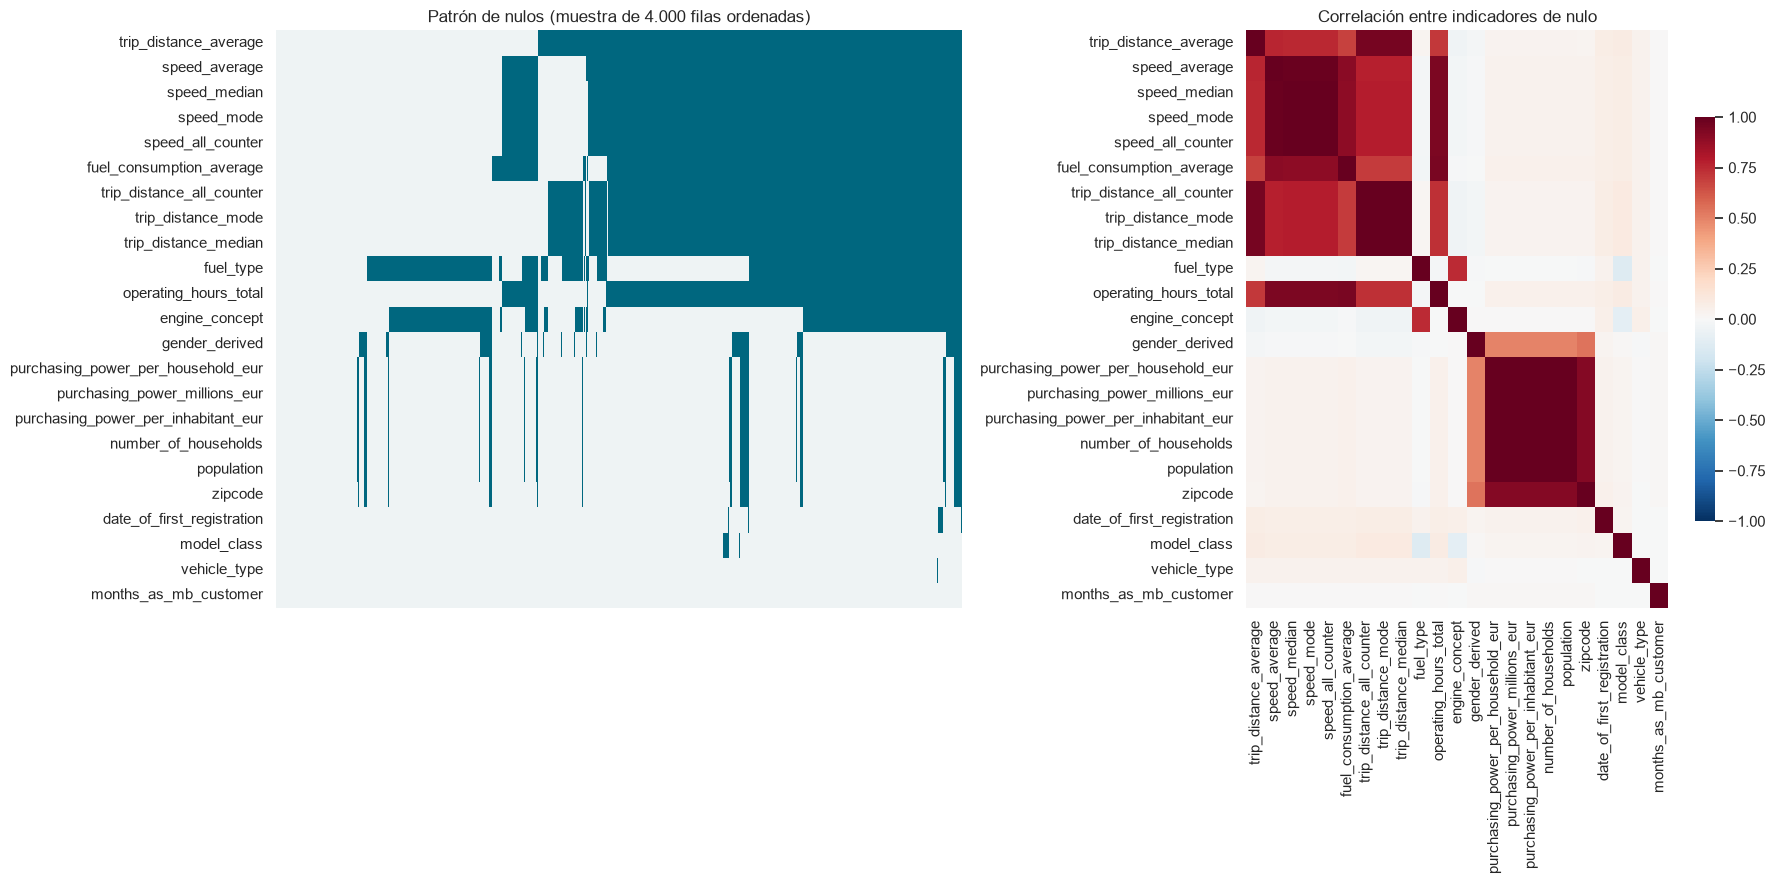

In [9]:
cols_con_nulos = nulos.index.tolist()[::-1]
muestra = df.sample(4000, random_state=0)[cols_con_nulos].isna()
fig, axes = plt.subplots(1, 2, figsize=(18, 9), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(muestra.sort_values(cols_con_nulos).T, cbar=False, cmap=["#eef3f4", AZUL], xticklabels=False, ax=axes[0])
axes[0].set(title="Patrón de nulos (muestra de 4.000 filas ordenadas)")
sns.heatmap(df[cols_con_nulos].isna().corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1], cbar_kws={"shrink": .7})
axes[1].set(title="Correlación entre indicadores de nulo")
plt.tight_layout()
plt.show()

In [10]:
cols_tel = ["trip_distance_average", "trip_distance_mode", "trip_distance_median", "trip_distance_all_counter",
            "operating_hours_total", "fuel_consumption_average", "speed_average", "speed_mode", "speed_median",
            "speed_all_counter"]
patrones = df[cols_tel].isna().value_counts().head(8).rename("filas").to_frame()
patrones["% filas"] = patrones["filas"] / n_rows * 100
patrones

filas  \
trip_distance_average trip_distance_mode trip_distance_median trip_distance_all_counter operating_hours_total fuel_consumption_average speed_average speed_mode speed_median speed_all_counter           
True                  True               True                 True                      True                  True                     True          True       True         True               156819   
False                 False              False                False                     False                 False                    False         False      False        False               96680   
                                                                                        True                  True                     True          True       True         True                15587   
True                  True               True                 True                      False                 False                    False         False      False        False               14151   
                                                                                                                                       True          True       True         True                 7009   
False                 False              False                False                     False                 True                     False         False      False        False                4449   
True                  False              False                False                     False                 False                    False         False      False        False                3276   
                                                                                                              True                     False         False      False        False                1113   

                                                                                                                                                                                                % filas  
trip_distance_average trip_distance_mode trip_distance_median trip_distance_all_counter operating_hours_total fuel_consumption_average speed_average speed_mode speed_median speed_all_counter           
True                  True               True                 True                      True                  True                     True          True       True         True                 51.78  
False                 False              False                False                     False                 False                    False         False      False        False                31.92  
                                                                                        True                  True                     True          True       True         True                  5.15  
True                  True               True                 True                      False                 False                    False         False      False        False                 4.67  
                                                                                                                                       True          True       True         True                  2.31  
False                 False              False                False                     False                 True                     False         False      False        False                 1.47  
True                  False              False                False                     False                 False                    False         False      False        False                 1.08  
                                                                                                              True                     False         False      False        False                 0.37

La telemetría falta casi siempre **en bloque** (todas las columnas a la vez). Hay patrones parciales: filas con
horas de funcionamiento pero sin trayectos, y filas con todo salvo el consumo (propio de vehículos enchufables).

### 3.3 ¿Por qué falta? Nulos por subgrupo

El tratamiento correcto depende del **mecanismo**:
- **Aleatorio** (MCAR): el nulo no depende de nada. Imputar o eliminar apenas sesga.
- **Depende de otras variables observadas** (MAR): el nulo se concentra en ciertos grupos. Eliminar esas filas
  **sesga la muestra**, e imputar debe hacerse **dentro del grupo**.
- **Estructural** (no aplica / no se mide): el dato no existe para ese caso. **No se debe imputar**: se
  inventaría un valor que no tiene sentido.

Para distinguirlos, comparamos el % de nulos entre subgrupos.

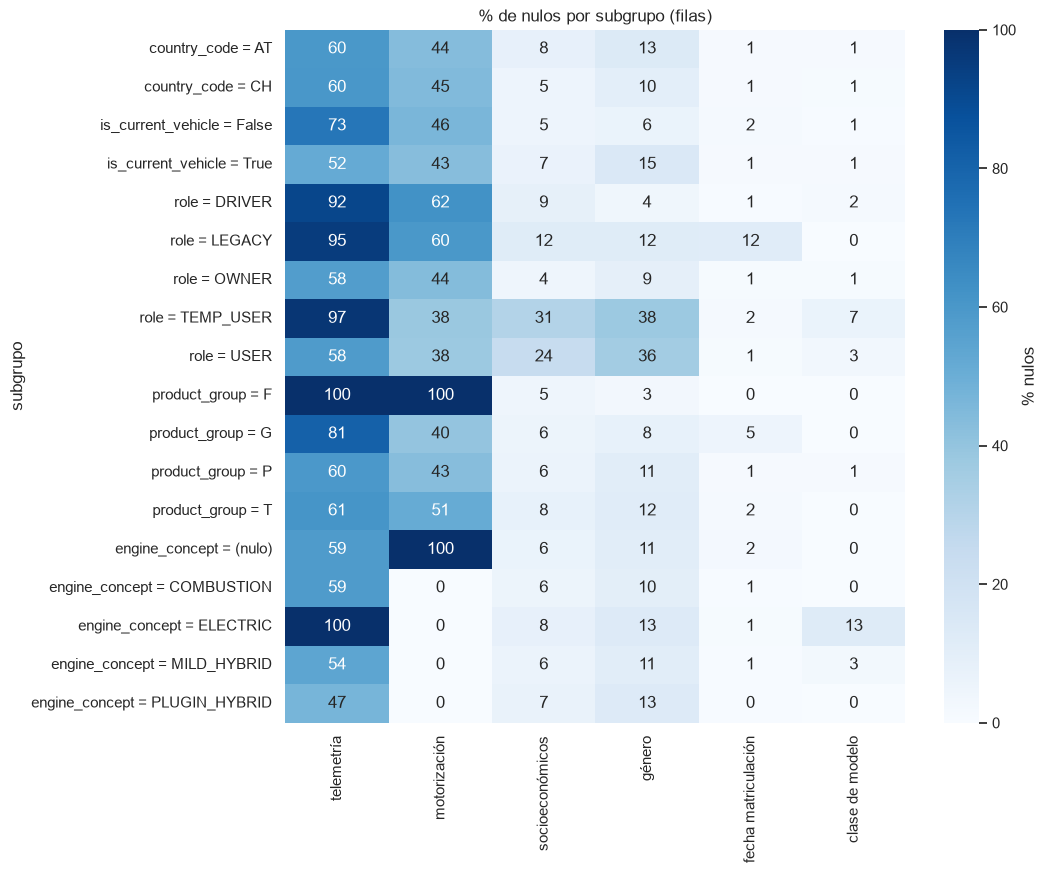

In [11]:
reg = pd.to_datetime(df["date_of_first_registration"], errors="coerce")
FECHA_REF = reg.max()  # fecha de referencia del extracto: la matriculación más reciente
df["anio_matriculacion"] = reg.dt.year
df["engine_concept_"] = df["engine_concept"].fillna("(nulo)")
cols_mec = {"speed_average": "telemetría", "engine_concept": "motorización", "purchasing_power_per_household_eur": "socioeconómicos",
            "gender_derived": "género", "date_of_first_registration": "fecha matriculación", "model_class": "clase de modelo"}
filas = []
for var in ["country_code", "is_current_vehicle", "role", "product_group", "engine_concept_"]:
    for valor, g in df.groupby(var):
        fila = {"subgrupo": f"{var.rstrip('_')} = {valor}", "filas": len(g)}
        fila.update({nombre: g[c].isna().mean() * 100 for c, nombre in cols_mec.items()})
        filas.append(fila)
tabla_mec = pd.DataFrame(filas).set_index("subgrupo")
plt.figure(figsize=(10, 9))
sns.heatmap(tabla_mec.drop(columns="filas"), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% nulos"})
plt.title("% de nulos por subgrupo (filas)")
plt.show()

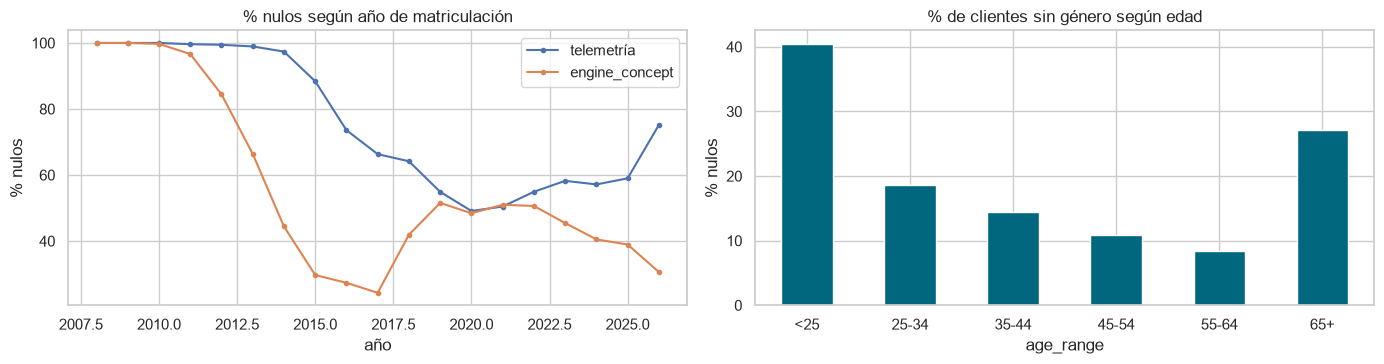

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
(df.groupby("anio_matriculacion")[["speed_average", "engine_concept"]].apply(lambda g: g.isna().mean() * 100)
   .loc[2008:].rename(columns={"speed_average": "telemetría", "engine_concept": "engine_concept"})
   .plot(ax=axes[0], marker="o", ms=3, title="% nulos según año de matriculación", ylabel="% nulos", xlabel="año"))
clientes = df.drop_duplicates("client_id")
orden_edad = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
(clientes.groupby("age_range")["gender_derived"].apply(lambda s: s.isna().mean() * 100).reindex(orden_edad)
   .plot.bar(ax=axes[1], color=AZUL, rot=0, title="% de clientes sin género según edad", ylabel="% nulos"))
plt.tight_layout()
plt.show()

**Lectura por bloque:**

- **Telemetría → estructural.** Falta en el **100 % de los eléctricos** (el sistema no la recoge para BEV), en el
  **92-97 % de los roles no propietarios** (DRIVER, LEGACY, TEMP_USER), en casi todos los coches **anteriores a 2016**
  (sin hardware conectado) y en el 100 % de los smart. No falta "porque sí": **no existe** para esos casos. Imputarla
  inventaría conducción; y usar "tiene telemetría" como rasgo del cliente mezclaría *eléctrico*, *coche antiguo* y
  *no propietario*. → **Ni imputar ni usar en el modelo**; solo para describir clusters, con esa advertencia.
- **Motorización → sistema de origen.** El % de nulos varía con el año de forma irregular (84 % en 2012, 24 % en
  2017, ~50 % en 2019-2022) y no por país: depende de qué sistema registró el vehículo. → Categoría `UNKNOWN` y
  deducción por nombre comercial (`EQ…`, `… e`, `… de`, `electric`).
- **Socioeconómicos → depende del país y del rol**: 8 % en AT frente a 5 % en CH, y 24-31 % en relaciones USER y
  TEMP_USER frente al 4 % de OWNER (clientes de los que no consta dirección). Además hay códigos postales sin cruce.
  → Imputar **dentro de cada país**. No eliminar: se perderían sobre todo los usuarios no propietarios.
- **Género → depende de la edad y del país**: falta en el 40 % de los menores de 25 y el 27 % de los mayores de 65,
  frente al 9-11 % de 45-64; y más en AT (21 %) que en CH (15 %). → **No eliminar** (sesgaría la edad) ni imputar con
  la moda (convertiría a 1 de cada 6 clientes en "hombre" sin base). También falta mucho más en USER y TEMP_USER
  (36-38 %). Categoría `unknown`.
- **Fecha de matriculación → depende del rol**: falta en el 12 % de las relaciones LEGACY (vehículos antiguos
  heredados de otro sistema) y en el 5 % de los G-Class; en el resto, ~1 %. El volumen total es pequeño (1,4 %).
- **Clase de modelo → modelos nuevos**: falta en el 13 % de los eléctricos (gamas EQ recientes sin clase asignada).
  Se deduce del nombre comercial.

### 3.4 ¿Media, mediana o eliminar? El efecto de cada opción

**Poder adquisitivo.** Se usa el poder adquisitivo **por habitante**: el apartado 6.2 muestra que el de "por hogar"
está inflado en las zonas rurales, donde los hogares son más grandes. Comparamos imputar con la media global, la
mediana global o la mediana de cada país.

,mean,median,min,max,skew
country_code,,,,,
AT,"30,346.95","30,177.61","19,701.53","48,329.54",0.57
CH,"55,362.50","51,433.60","26,659.85","148,353.74",2.54
global,"47,189.33","46,753.32","19,701.53","148,353.74",1.68


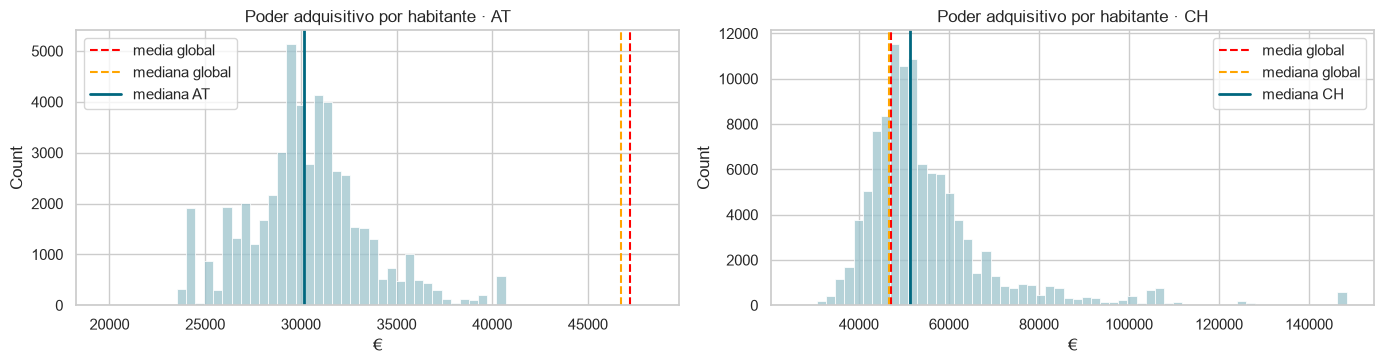

Un cliente austriaco imputado con la media global quedaría por encima del 88 % de los austriacos.


In [13]:
pp = "purchasing_power_per_inhabitant_eur"   # por habitante, no por hogar: ver 6.2
estad = clientes.groupby("country_code")[pp].agg(["mean", "median", "min", "max", "skew"])
estad.loc["global"] = [clientes[pp].mean(), clientes[pp].median(), clientes[pp].min(), clientes[pp].max(), clientes[pp].skew()]
display(estad.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, pais in zip(axes, ["AT", "CH"]):
    s = clientes.loc[clientes["country_code"] == pais, pp].dropna()
    sns.histplot(s, bins=60, ax=ax, color=AZUL_CLARO)
    ax.axvline(estad.loc["global", "mean"], color="red", ls="--", label="media global")
    ax.axvline(estad.loc["global", "median"], color="orange", ls="--", label="mediana global")
    ax.axvline(estad.loc[pais, "median"], color=AZUL, lw=2, label=f"mediana {pais}")
    ax.set(title=f"Poder adquisitivo por habitante · {pais}", xlabel="€")
    ax.legend()
plt.tight_layout()
plt.show()
p_at = (clientes.loc[clientes["country_code"] == "AT", pp] < estad.loc["global", "mean"]).mean() * 100
print(f"Un cliente austriaco imputado con la media global quedaría por encima del {p_at:.0f} % de los austriacos.")

- La **media global** (47 k€) y la **mediana global** (47 k€) caen en la cola alta de Austria, cerca de su máximo
  (48 k€): un cliente austriaco sin dato pasaría a estar por encima del 88 % de su país. **Imputación global
  descartada.**
- Dentro de CH la distribución es **muy asimétrica** (asimetría 2,5): la media (55 k€) está inflada por zonas muy
  ricas y no representa al cliente típico (mediana 51 k€). **Media descartada.**
- **Decisión: mediana de su país.** En el Reto 2 la variable se usa como percentil dentro del país, y el nulo pasa a
  0,5, que es exactamente la mediana del país.

**¿Y si eliminamos los clientes con nulos?** Simulamos eliminar los clientes sin género o sin poder adquisitivo.

In [14]:
completos = clientes.dropna(subset=["gender_derived", pp])
perdida = 1 - len(completos) / len(clientes)
comp = pd.DataFrame({
    "todos": clientes["age_range"].value_counts(normalize=True),
    "sin nulos": completos["age_range"].value_counts(normalize=True),
}).reindex(orden_edad).mul(100)
comp.loc["AT (país)"] = [(clientes["country_code"] == "AT").mean() * 100, (completos["country_code"] == "AT").mean() * 100]
comp["diferencia (pp)"] = comp["sin nulos"] - comp["todos"]
print(f"Se perderían {len(clientes) - len(completos):,} clientes ({perdida:.1%})")
comp.round(1)

Se perderían 32,272 clientes (18.6%)


,todos,sin nulos,diferencia (pp)
age_range,,,
<25,4.70,3.40,-1.40
25-34,15.50,15.20,-0.30
35-44,18.90,19.50,0.70
45-54,21.00,22.70,1.70
55-64,19.60,21.80,2.10
65+,20.20,17.40,-2.80
AT (país),33.80,31.80,-2.00


Eliminar perdería el **18,6 % de los clientes** y además **cambiaría el perfil** de la base: menos jóvenes (<25),
menos mayores (65+) y menos austriacos. Los segmentos resultantes describirían una población que no es la real.
**Eliminar filas queda descartado** para todas las columnas; los nulos se tratan con imputación por grupo o con
categorías explícitas.

### 3.5 Decisión columna a columna

| Columna | % filas | % clientes | Mecanismo | Opciones valoradas | Decisión | Consecuencia |
|---|---|---|---|---|---|---|
| Telemetría (10 columnas) | 57-61 | 46-50 | Estructural: BEV, roles no propietarios, coches < 2016 | Imputar mediana · eliminar filas · flag "tiene telemetría" | **Ni imputar ni modelar**. Solo para perfilar, con advertencia | Se pierde la conducción como rasgo, pero se evita inventar datos o penalizar a los eléctricos |
| `fuel_type` | 59 | 50 | Sistema de origen; redundante | Imputar · usar | **Excluir** (usar `engine_concept`) | Ninguna: `engine_concept` contiene la misma información con menos nulos |
| `engine_concept` | 44 | 36 | Sistema de origen (varía por año, no por país) | Moda (COMBUSTION) · eliminar · `UNKNOWN` + deducción por nombre | **Deducir electrificación por nombre**; resto `UNKNOWN` | Algún híbrido sin sufijo puede quedar como no electrificado (subestimación leve) |
| `gender_derived` | 11 | 17 | Depende de edad y país | Eliminar · moda ("male") · `unknown` | **Categoría `unknown`**; fuera del modelo | Sin sesgo de edad; el género solo describe |
| Socioeconómicos (5 columnas) | 6,3 | 8,9 | Depende del país + CP sin cruce | Media / mediana global · eliminar · mediana del país | **Mediana del país** (percentil 0,5) y una sola variable | Un 9 % de clientes queda en el centro de su país: atenúa algo la variable, sin desplazar a nadie |
| `zipcode` | 5,3 | 8,3 | Igual que socioeconómicos | — | **Excluir** (identificador) | — |
| `date_of_first_registration` | 1,4 | 0,8 | Depende del rol (12 % en LEGACY) y algo más en G-Class | Eliminar · mediana global · mediana por gama | **Antigüedad del vehículo: mediana** (si el cliente tiene otro vehículo con fecha, se usa ese) | Afecta a 1.348 clientes (0,8 %): efecto despreciable |
| `model_class` | 1,1 | 0,7 | Modelos nuevos (GLC 400, GLB 350, CLA…) | `UNKNOWN` · deducir | **Deducir por prefijo de `vehicle_type`** | Gama recuperada casi al 100 % |
| `vehicle_type` | 0,3 | — | Residual | — | Sin acción | — |
| `months_as_mb_customer` | < 0,01 | 2 clientes | Residual (clientes sin vehículo actual) | Eliminar · mediana | **Mediana** | Irrelevante (2 clientes) |

## 4. Inconsistencias y detalles del dato

In [15]:
z = df["zipcode"].dropna()
tm = pd.to_numeric(df["trip_distance_median"], errors="coerce")
checks = {
    "fecha de matriculación posterior a la fecha de referencia": (reg > FECHA_REF).sum(),
    "fecha de matriculación anterior a 1990": (reg < "1990-01-01").sum(),
    "zipcode con formato no numérico (CH-6340, A-2100, 'Ottenbach')": (~z.str.fullmatch(r"\d+")).sum(),
    "zipcode con longitud distinta de 4": (z.str.len() != 4).sum(),
    "zipcode informado sin datos socioeconómicos (sin cruce)": (df["zipcode"].notna() & df[pp].isna()).sum(),
    "population = 0 con poder adquisitivo informado": ((df["population"] == 0) & df[pp].notna()).sum(),
    "months_as_mb_customer nulo": df["months_as_mb_customer"].isna().sum(),
    "clientes con months_as_mb_customer = 0": (clientes["months_as_mb_customer"] == 0).sum(),
    "clientes con months_as_mb_customer = 36 (pico)": (clientes["months_as_mb_customer"] == 36).sum(),
    "clientes con 0 vehículos conectados (inactivos)": (clientes["currently_connected_vehicles"] == 0).sum(),
    "clientes con vehículos actuales ≠ currently_connected_vehicles": None,
    "filas con 0 trayectos pero con mediana de trayecto": ((df["trip_distance_all_counter"] == 0) & tm.notna()).sum(),
    "filas con horas de funcionamiento = 0": (df["operating_hours_total"] == 0).sum(),
    "modas con varios valores (texto con comas)": df["trip_distance_mode"].str.contains(",", na=False).sum() + df["speed_mode"].str.contains(",", na=False).sum(),
    "ELECTRIC con consumo de combustible informado": ((df["engine_concept"] == "ELECTRIC") & df["fuel_consumption_average"].notna()).sum(),
    "B2B con rol distinto de DRIVER": ((df["role_type"] == "B2B") & (df["role"] != "DRIVER")).sum(),
}
act = df.groupby("client_id").agg(a=("is_current_vehicle", "sum"), d=("currently_connected_vehicles", "first"))
checks["clientes con vehículos actuales ≠ currently_connected_vehicles"] = (act["a"] != act["d"]).sum()
print("Fecha de referencia del extracto:", FECHA_REF.date())
pd.Series(checks, name="casos").to_frame()

Fecha de referencia del extracto: 2026-10-02


,casos
fecha de matriculación posterior a la fecha de referencia,0
fecha de matriculación anterior a 1990,2
"zipcode con formato no numérico (CH-6340, A-2100, 'Ottenbach')",4
zipcode con longitud distinta de 4,5
zipcode informado sin datos socioeconómicos (sin cruce),2952
population = 0 con poder adquisitivo informado,0
months_as_mb_customer nulo,4
clientes con months_as_mb_customer = 0,7254
clientes con months_as_mb_customer = 36 (pico),21179
clientes con 0 vehículos conectados (inactivos),18047


### Valores discretizados y topes del sistema de origen

In [16]:
lims = pd.DataFrame({c: {"mín": df[c].min(), "casos en el mín": (df[c] == df[c].min()).sum(),
                         "máx": df[c].max(), "casos en el máx": (df[c] == df[c].max()).sum(),
                         "valores distintos": df[c].nunique()}
                     for c in ["fuel_consumption_average", "trip_distance_average", "speed_average",
                               "trip_distance_median", "speed_median", "operating_hours_total"]}).T
display(lims)
print("Valores posibles de trip_distance_median:", sorted(tm.dropna().unique()))

,mín,casos en el mín,máx,casos en el máx,valores distintos
fuel_consumption_average,3.00,20.00,50.00,8.00,"2,267.00"
trip_distance_average,1.00,634.00,300.00,34.00,"5,476.00"
speed_average,0.12,228.00,220.00,10.00,"8,248.00"
trip_distance_median,1.00,"4,875.00",300.00,38.00,13.00
speed_median,0.12,"3,895.00",220.00,10.00,12.00
operating_hours_total,0.00,140.00,"26,842.00",1.00,"80,943.00"


Valores posibles de trip_distance_median: [np.float64(1.0), np.float64(2.5), np.float64(3.0), np.float64(7.5), np.float64(10.0), np.float64(15.0), np.float64(22.5), np.float64(27.5), np.float64(42.5), np.float64(62.5), np.float64(87.5), np.float64(150.0), np.float64(300.0)]


- **Medianas y modas de trayecto y velocidad**: solo toman 12-13 valores (1; 2,5; 3; 7,5; 10…). Son **límites de
  los tramos** de un histograma que guarda el vehículo, no medianas reales. Las modas, además, son texto cuando hay
  empate ("3,7.5"). → Se excluyen; para describir la conducción se usan las **medias**.
- **Topes**: consumo entre 3 y 50, distancia media entre 1 y 300 km, velocidad media entre 0,12 y 220 km/h, con
  acumulación de casos justo en los extremos. Son límites del sistema de origen: los valores en el tope significan
  "≥ tope". → Para describir se usan **medianas**, que no se ven afectadas.
- **0 trayectos con mediana informada** (6.027 filas): la mediana toma el valor del primer tramo por defecto. Más
  motivo para no usarla.
- **Pico en `months_as_mb_customer` = 36**: 21.179 clientes (12 %) frente a ~2.700 en 35 o 37 meses. Es casi
  seguro un artefacto (fecha de alta masiva o migración de sistema). Se mantiene (no hay forma de recuperar el valor
  real), pero se interpreta como "unos 3 años o más" para esos clientes.
- **Códigos postales**: 4 con formato erróneo y 2.952 filas cuyo CP no cruza con la tabla socioeconómica. Ambos casos
  acaban como nulo socioeconómico y se imputan con la mediana del país.
- **4 clientes** con un desajuste de 1 entre vehículos actuales y `currently_connected_vehicles`: irrelevante; se usa
  el campo declarado.

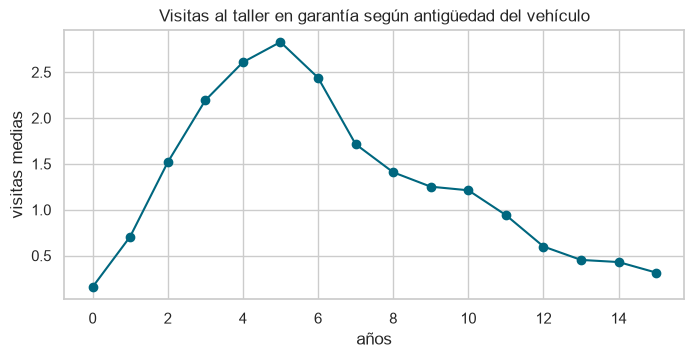

In [17]:
# Las visitas al taller dependen de la edad del coche: solo cuentan las de garantía / goodwill
edad_veh = (FECHA_REF - reg).dt.days / 365.25
ax = df.groupby(edad_veh.clip(upper=15).round())["workshop_visits_warranty_goodwill"].mean().plot(marker="o", color=AZUL, figsize=(8, 3.5))
ax.set(title="Visitas al taller en garantía según antigüedad del vehículo", xlabel="años", ylabel="visitas medias")
plt.show()

Las visitas crecen hasta ~5 años y después **bajan**: al terminar la garantía dejan de registrarse. Un coche nuevo
tiene pocas visitas porque no le ha dado tiempo, no porque su dueño cuide menos el coche. Hay que tenerlo en cuenta
al interpretar esta variable.

### Visitas al taller por país: diferencia de registro

In [18]:
cli_visitas = df.assign(antig=edad_veh).groupby("client_id").agg(visitas=("workshop_visits_warranty_goodwill", "mean"),
                                                                 pais=("country_code", "first"),
                                                                 antig=("antig", "median"))
tabla = pd.crosstab(cli_visitas["pais"], cli_visitas["visitas"].clip(upper=6).round(), normalize="index").mul(100)
tabla.columns = [f"{int(c)}{'+' if c == 6 else ''}" for c in tabla.columns]
tabla["antigüedad mediana del vehículo"] = cli_visitas.groupby("pais")["antig"].median()
tabla.round(1)

,0,1,2,3,4,5,6+,antigüedad mediana del vehículo
pais,,,,,,,,
AT,52.10,20.70,13.30,5.60,3.60,1.70,3.00,4.60
CH,22.60,15.70,19.70,13.20,10.90,6.10,11.80,4.90


Con coches de antigüedad similar, el **52 % de los clientes austriacos tiene 0 visitas** frente al 23 % de los
suizos. Es una diferencia de **registro** entre mercados más que de comportamiento. → En el Reto 2 las visitas se
expresan como percentil dentro del país.

## 5. Estadísticas descriptivas y distribuciones

In [19]:
num_cliente = ["months_as_mb_customer", "currently_connected_vehicles", "purchasing_power_per_inhabitant_eur",
               "purchasing_power_per_household_eur", "population", "number_of_households", "purchasing_power_millions_eur"]
desc = clientes[num_cliente].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["asimetría"] = clientes[num_cliente].skew()
desc

,count,mean,std,min,5%,25%,50%,75%,95%,max,asimetría
months_as_mb_customer,"173,454.00",33.90,20.73,0.00,1.00,18.00,36.00,47.00,67.00,120.00,0.40
currently_connected_vehicles,"173,456.00",1.04,0.88,0.00,0.00,1.00,1.00,1.00,2.00,21.00,10.80
purchasing_power_per_inhabitant_eur,"158,097.00","47,189.33","17,304.08","19,701.53","27,169.71","32,072.80","46,753.32","54,750.58","77,483.13","148,353.74",1.68
purchasing_power_per_household_eur,"158,097.00","106,347.13","41,929.36","45,087.34","58,381.26","72,810.07","103,738.42","123,410.83","184,202.62","342,497.95",1.67
population,"158,140.00","20,066.46","37,090.01",0.00,"1,011.00","3,132.00","7,364.00","18,501.00","101,714.00","220,794.00",3.63
number_of_households,"158,140.00","9,531.86","17,902.72",0.00,432.00,"1,336.00","3,278.00","8,920.00","50,850.00","102,998.00",3.47
purchasing_power_millions_eur,"158,097.00",756.28,"1,045.49",0.65,41.71,140.43,347.92,943.57,"2,904.52","5,998.91",2.73


In [20]:
num_rel = ["workshop_visits_warranty_goodwill", "trip_distance_average", "operating_hours_total",
           "fuel_consumption_average", "speed_average"]
desc_rel = df[num_rel].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc_rel["asimetría"] = df[num_rel].skew()
desc_rel

,count,mean,std,min,5%,25%,50%,75%,95%,max,asimetría
workshop_visits_warranty_goodwill,"302,850.00",1.75,2.43,0.00,0.00,0.00,1.00,3.00,7.00,44.00,2.19
trip_distance_average,"116,993.00",16.16,10.67,1.00,5.93,10.15,14.02,19.53,32.96,300.00,7.62
operating_hours_total,"128,492.00",620.27,742.61,0.00,7.64,137.48,406.51,855.95,"1,885.39","26,842.00",4.06
fuel_consumption_average,"122,125.00",8.56,3.26,3.00,5.07,6.58,8.11,9.72,13.54,50.00,3.60
speed_average,"120,468.00",48.67,14.21,0.12,25.40,41.23,49.34,57.25,69.97,220.00,-0.30


Casi todas las variables numéricas son **asimétricas a la derecha** (asimetría > 1): la mediana describe mejor al
cliente típico que la media, y en el modelo hará falta transformarlas (log) o recortarlas.

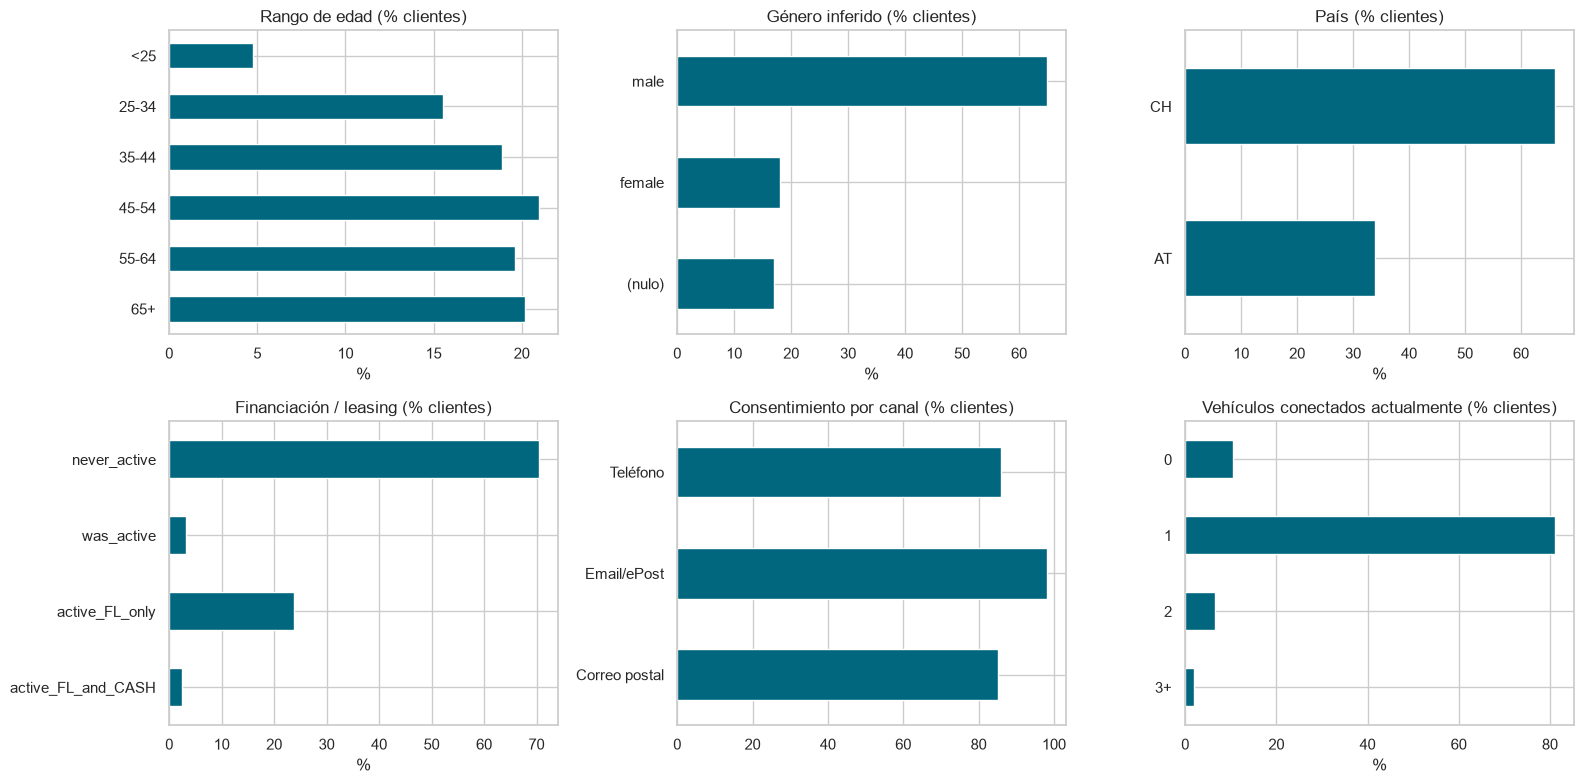

In [21]:
def barras(ax, s, titulo, orden=None, top=None):
    vc = s.fillna("(nulo)").value_counts(normalize=True).mul(100)
    vc = vc.reindex(orden) if orden else vc
    vc = vc.head(top) if top else vc
    vc.plot.barh(ax=ax, color=AZUL)
    ax.invert_yaxis()
    ax.set(title=titulo, xlabel="%", ylabel="")

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
barras(axes[0, 0], clientes["age_range"], "Rango de edad (% clientes)", orden=orden_edad)
barras(axes[0, 1], clientes["gender_derived"], "Género inferido (% clientes)")
barras(axes[0, 2], clientes["country_code"], "País (% clientes)")
barras(axes[1, 0], clientes["finance_leasing_status"], "Financiación / leasing (% clientes)",
       orden=["never_active", "was_active", "active_FL_only", "active_FL_and_CASH"])
consent = clientes[["consent_phone_communication_channel", "consent_epost_communication_channel",
                    "consent_post_communication_channel"]].mean().mul(100)
consent.index = ["Teléfono", "Email/ePost", "Correo postal"]
consent.plot.barh(ax=axes[1, 1], color=AZUL, title="Consentimiento por canal (% clientes)")
axes[1, 1].invert_yaxis()
barras(axes[1, 2], clientes["currently_connected_vehicles"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"}),
       "Vehículos conectados actualmente (% clientes)", orden=["0", "1", "2", "3+"])
plt.tight_layout()
plt.show()

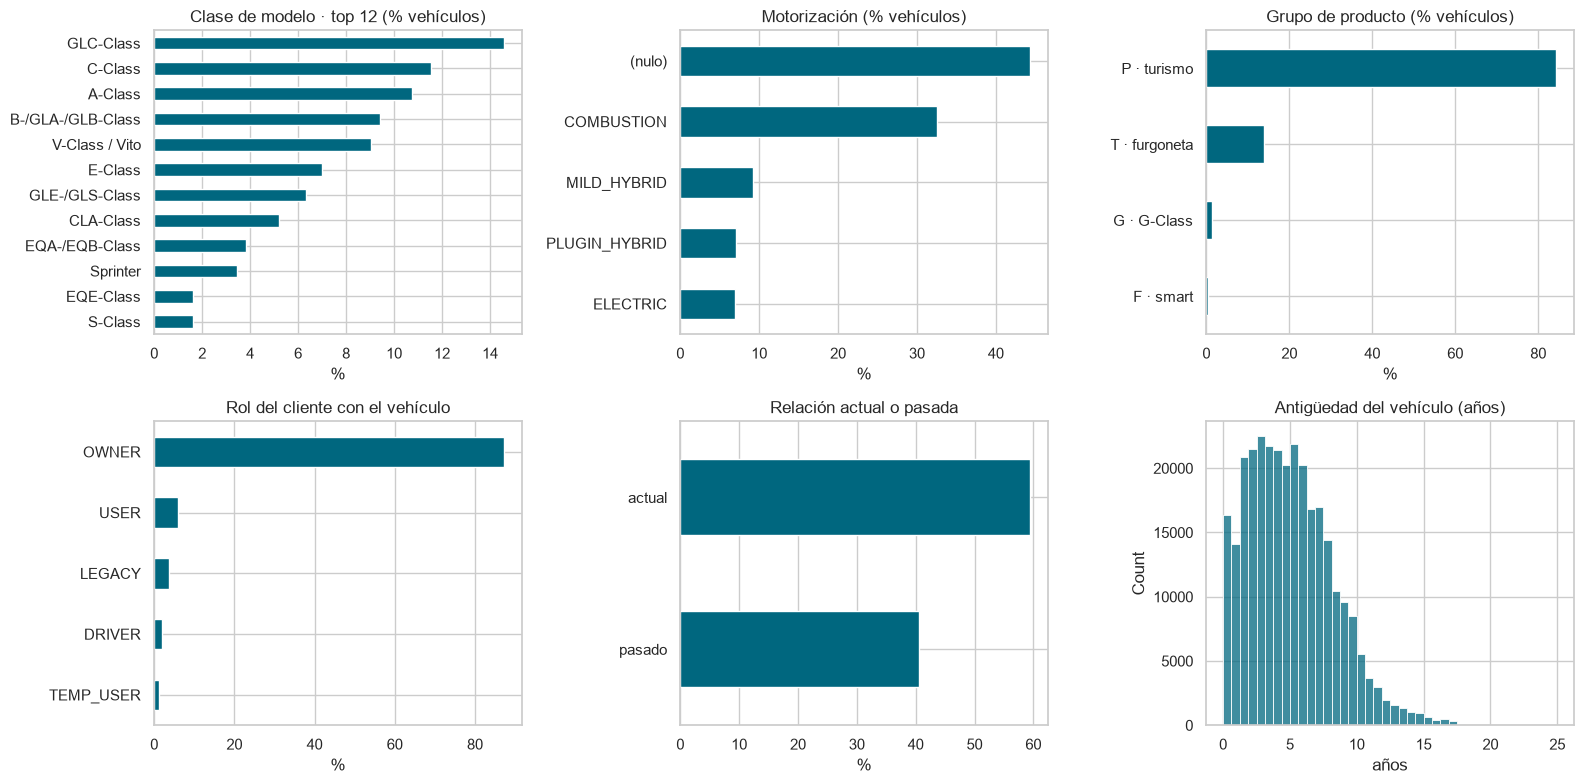

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
barras(axes[0, 0], df["model_class"], "Clase de modelo · top 12 (% vehículos)", top=12)
barras(axes[0, 1], df["engine_concept"], "Motorización (% vehículos)")
barras(axes[0, 2], df["product_group"].map({"P": "P · turismo", "T": "T · furgoneta", "G": "G · G-Class", "F": "F · smart"}),
       "Grupo de producto (% vehículos)")
barras(axes[1, 0], df["role"], "Rol del cliente con el vehículo")
barras(axes[1, 1], df["is_current_vehicle"].map({True: "actual", False: "pasado"}), "Relación actual o pasada")
sns.histplot(edad_veh.dropna(), bins=40, binrange=(0, 25), ax=axes[1, 2], color=AZUL)
axes[1, 2].set(title="Antigüedad del vehículo (años)", xlabel="años")
plt.tight_layout()
plt.show()

### Separando por país

Austria y Suiza son mercados distintos. Antes de agregar conclusiones, se comprueba qué variables cambian entre ellos.

In [23]:
cmp = pd.DataFrame({
    "edad 45+ (%)": clientes.groupby("country_code")["age_range"].apply(lambda s: s.isin(["45-54", "55-64", "65+"]).mean() * 100),
    "leasing activo (%)": clientes.groupby("country_code")["finance_leasing_status"].apply(lambda s: s.str.startswith("active").mean() * 100),
    "meses como cliente (mediana)": clientes.groupby("country_code")["months_as_mb_customer"].median(),
    "poder adquisitivo por habitante (mediana, €)": clientes.groupby("country_code")[pp].median(),
    "electrificados (% vehículos con motor conocido)": df[df["engine_concept"].notna()].groupby("country_code")["engine_concept"].apply(lambda s: s.isin(["PLUGIN_HYBRID", "ELECTRIC"]).mean() * 100),
    "furgonetas (% vehículos)": df.groupby("country_code")["product_group"].apply(lambda s: (s == "T").mean() * 100),
    "visitas taller por vehículo (media)": df.groupby("country_code")["workshop_visits_warranty_goodwill"].mean(),
    "género desconocido (% clientes)": clientes.groupby("country_code")["gender_derived"].apply(lambda s: s.isna().mean() * 100),
}).T
cmp.round(1)

country_code,AT,CH
edad 45+ (%),63.20,59.60
leasing activo (%),15.60,31.60
meses como cliente (mediana),30.50,36.00
"poder adquisitivo por habitante (mediana, €)","30,177.60","51,433.60"
electrificados (% vehículos con motor conocido),33.50,20.20
furgonetas (% vehículos),17.40,11.80
visitas taller por vehículo (media),1.00,2.20
género desconocido (% clientes),21.50,14.60


Diferencias relevantes entre países:
- **Poder adquisitivo**: CH casi duplica a AT. → En el modelo, siempre **relativo al país**.
- **Visitas al taller**: diferencia de registro (ver apartado 4). → Relativo al país.
- **Leasing** (más en CH) y **electrificación** (más en AT): diferencias de mercado reales, se mantienen.

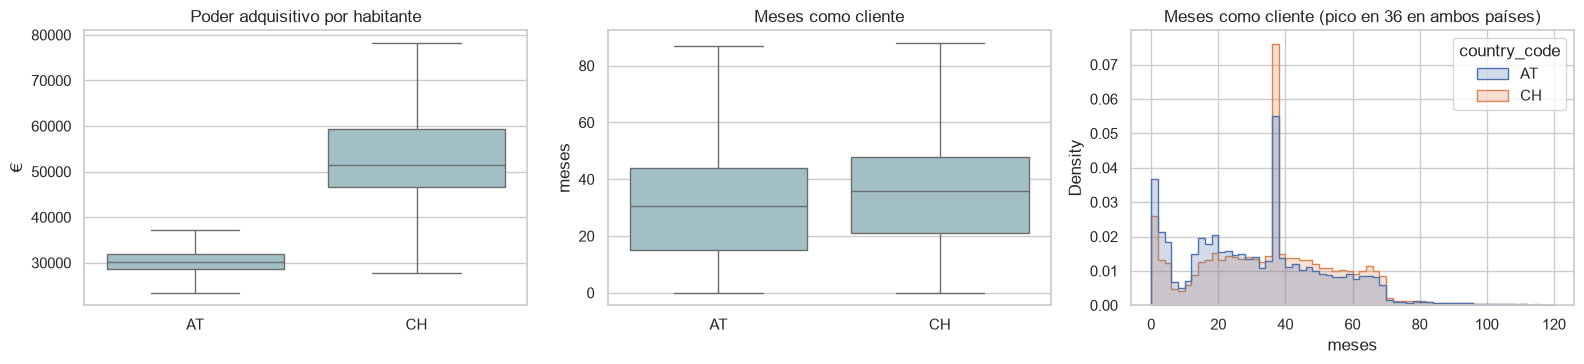

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.boxplot(data=clientes, x="country_code", y=pp, showfliers=False, ax=axes[0], color=AZUL_CLARO)
axes[0].set(title="Poder adquisitivo por habitante", xlabel="", ylabel="€")
sns.boxplot(data=clientes, x="country_code", y="months_as_mb_customer", showfliers=False, ax=axes[1], color=AZUL_CLARO)
axes[1].set(title="Meses como cliente", xlabel="", ylabel="meses")
sns.histplot(data=clientes, x="months_as_mb_customer", hue="country_code", bins=60, ax=axes[2], element="step", stat="density", common_norm=False)
axes[2].set(title="Meses como cliente (pico en 36 en ambos países)", xlabel="meses")
plt.tight_layout()
plt.show()

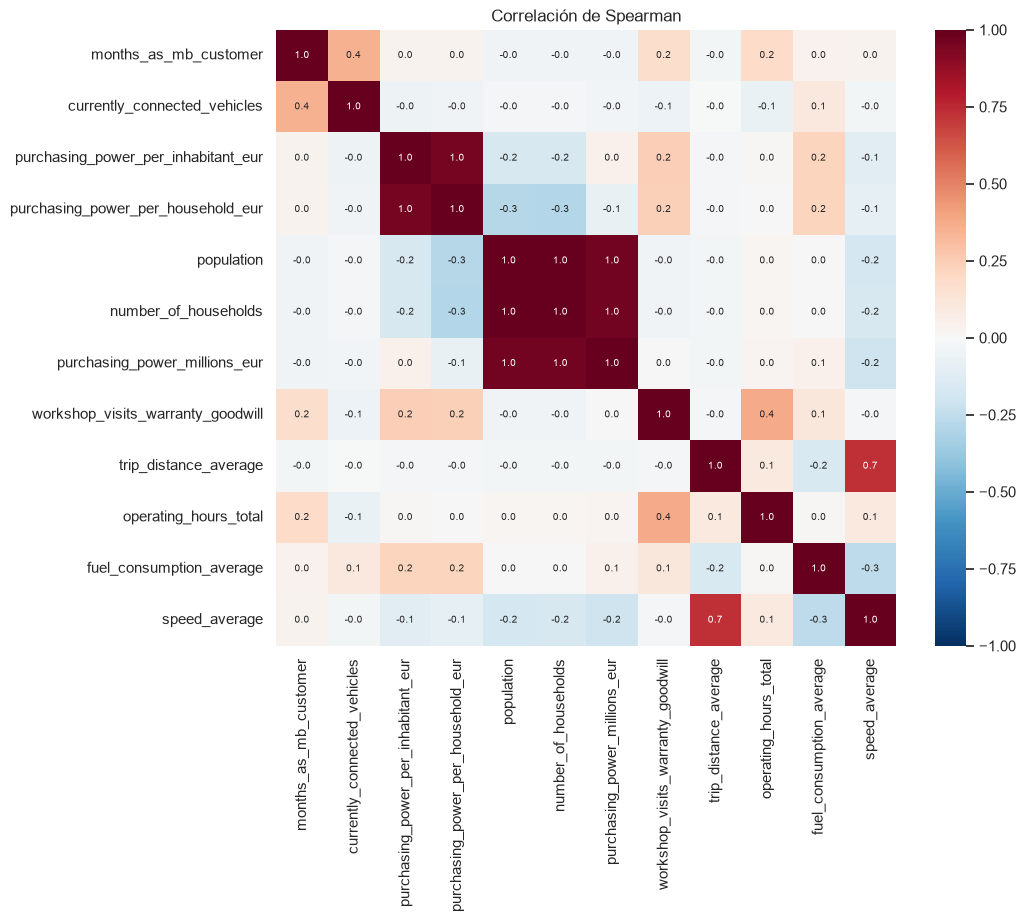

In [25]:
# Correlación (Spearman, robusta a asimetría y outliers) entre variables numéricas
corr = df[num_cliente + num_rel].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlación de Spearman")
plt.show()

Las cinco variables socioeconómicas forman dos bloques casi redundantes: **poder adquisitivo por habitante ≈ por
hogar** y **población ≈ hogares ≈ poder total** (tamaño de la zona, no riqueza del cliente). → Se usa una sola:
poder adquisitivo **por habitante**. Por hogar y por habitante parecen intercambiables (ρ ≈ 0,96), pero el cruce con
datos externos del apartado 6.2 muestra que el de por hogar está sesgado por el tamaño del hogar.

## 6. Relaciones no evidentes

Lo descriptivo del apartado 5 confirma lo que cualquiera esperaría (clientes maduros, mayoría de turismos, Suiza más
rica). Aquí se buscan relaciones **que no son obvias** y que cambian cómo se interpretan los datos o qué se le
ofrece al cliente, en dos niveles:
- **6.1 Dentro del propio CSV**: cruces entre edad, coche, uso, taller y relación con la marca.
- **6.2 Con datos oficiales externos** de salud y seguridad vial, unidos por código postal.

Para trabajar a nivel de cliente se usa la tabla de una fila por cliente que se formaliza en el Reto 2
(`agregar_clientes` de `features.py`).

**Regla para no engañarnos:** cada hallazgo se contrasta con su **explicación aburrida** (edad del coche, país,
ruralidad, poder adquisitivo) antes de darlo por bueno. Si desaparece al controlar por ella, no es un hallazgo.

In [26]:
from scipy.stats import spearmanr, rankdata
import os
from features import agregar_clientes, construir_tabla_salud, COLS_ZONA, COLS_SALUD, ORDEN_EDAD
if not os.path.exists("datos_salud_edad_sexo.csv"):
    construir_tabla_salud()      # descarga de la API de Eurostat (solo la primera vez; ver 6.3)
cli = agregar_clientes(df)
cli["inactivo"] = cli["n_vehiculos_actuales"].eq(0)
cli["leasing_activo"] = cli["finance_leasing_status"].str.startswith("active")
cli["banda_coche"] = pd.cut(cli["antiguedad_vehiculo"], [-1, 3, 6, 10, 60], labels=["0-3", "3-6", "6-10", "10+"])
df["antig"] = edad_veh

### 6.1 Dentro del CSV

#### a) Mayores de 65 con coche antiguo… que apenas usan

El cliente de 65+ tiene **el doble de coches de 10 años o más** que los de 35-64. Lo que no es evidente: **los usan
mucho menos**. Con telemetría (turismos), sus coches acumulan un **~20 % menos de horas de motor** que los de la
misma edad de otros clientes, y hacen trayectos más cortos.

Detalle: `operating_hours_total` es un **contador acumulado**, así que crece con la edad del coche. Por eso solo se
compara dentro de la misma banda de antigüedad. En coches de 10+ años el contador es más bajo para todos (la
telemetría empezó a registrarse más tarde que la matriculación) y la diferencia por edad casi desaparece.

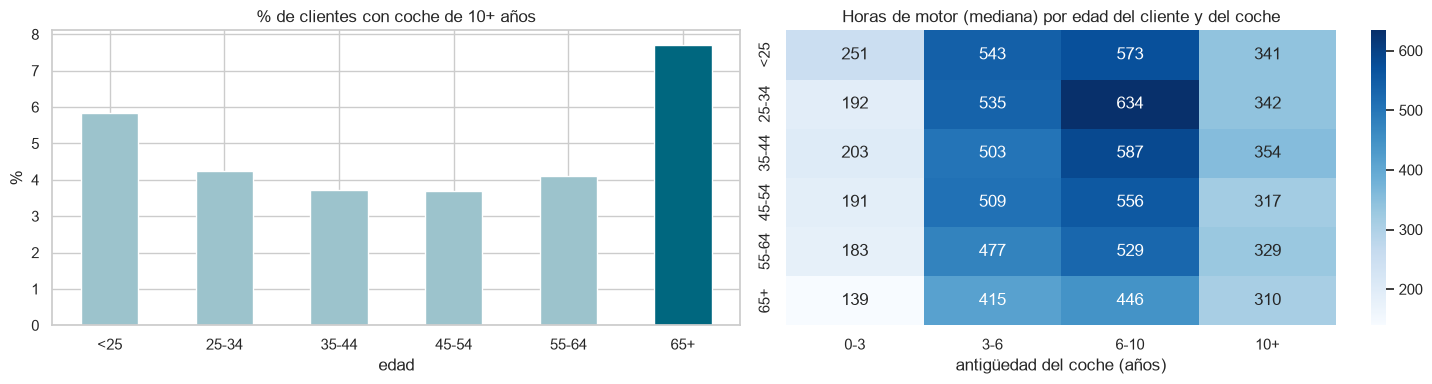

,operating_hours_total,trip_distance_average,speed_average
age_range,,,
<25,463.40,14.40,47.40
25-34,450.40,14.10,48.70
35-44,417.60,13.80,48.90
45-54,399.40,14.20,49.60
55-64,377.50,14.30,50.90
65+,320.10,12.70,48.10


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
p10 = cli.groupby("age_range")["antiguedad_vehiculo"].apply(lambda s: (s >= 10).mean() * 100).reindex(orden_edad)
p10.plot.bar(ax=axes[0], color=[AZUL_CLARO] * 5 + [AZUL], rot=0)
axes[0].set(title="% de clientes con coche de 10+ años", xlabel="edad", ylabel="%")
tel = df[df["speed_average"].notna() & df["product_group"].eq("P")].copy()
tel["banda"] = pd.cut(tel["antig"], [-1, 3, 6, 10, 60], labels=["0-3", "3-6", "6-10", "10+"])
horas = tel.pivot_table(index="age_range", columns="banda", values="operating_hours_total", aggfunc="median", observed=True).reindex(orden_edad)
sns.heatmap(horas, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set(title="Horas de motor (mediana) por edad del cliente y del coche", xlabel="antigüedad del coche (años)", ylabel="")
plt.tight_layout()
plt.show()
tel.groupby("age_range")[["operating_hours_total", "trip_distance_average", "speed_average"]].median().reindex(orden_edad).round(1)

**Lectura:** un coche antiguo de un cliente de 65+ es un coche **con pocos kilómetros**. Dos consecuencias:
- **Valor de recompra alto** para su edad: argumento de "tu coche vale más de lo que crees" para renovar.
- No necesita un coche grande ni potente: su cambio natural es un modelo **más nuevo y más seguro**, no más caro
  (asistentes de aparcamiento y frenada, seminuevo certificado).

#### b) Los híbridos enchufables que no se enchufan

Un híbrido enchufable (PHEV) cargado con regularidad consume muy poco combustible. Si casi nunca se carga, consume
como un coche de combustión (o más, porque pesa más por la batería).

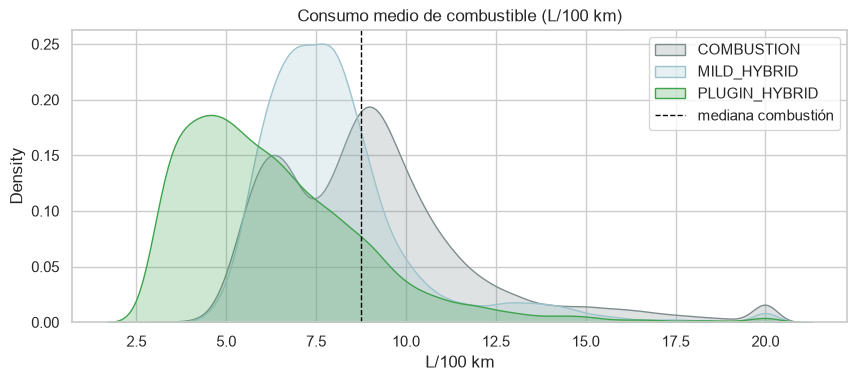

PHEV con telemetría de consumo                       7,747.00
consumo mediano PHEV (L/100 km)                          5.80
consumo mediano combustión (L/100 km)                    8.76
% PHEV que consumen como un combustión (≥ mediana)      15.21
% PHEV que consumen más de 6 L/100 km                   46.90
dtype: float64

In [28]:
cons = df[df["engine_concept"].isin(["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID"]) & df["fuel_consumption_average"].notna()]
med_comb = cons.loc[cons["engine_concept"] == "COMBUSTION", "fuel_consumption_average"].median()
fig, ax = plt.subplots(figsize=(10, 3.8))
for motor, color in [("COMBUSTION", "#7f8c8d"), ("MILD_HYBRID", AZUL_CLARO), ("PLUGIN_HYBRID", "#3fa34d")]:
    sns.kdeplot(cons.loc[cons["engine_concept"] == motor, "fuel_consumption_average"].clip(upper=20), ax=ax, label=motor, color=color, fill=True, alpha=.25)
ax.axvline(med_comb, color="black", ls="--", lw=1, label="mediana combustión")
ax.set(title="Consumo medio de combustible (L/100 km)", xlabel="L/100 km")
ax.legend()
plt.show()
phev = cons[cons["engine_concept"] == "PLUGIN_HYBRID"].drop_duplicates("vehicle_id")
pd.Series({
    "PHEV con telemetría de consumo": len(phev),
    "consumo mediano PHEV (L/100 km)": phev["fuel_consumption_average"].median(),
    "consumo mediano combustión (L/100 km)": med_comb,
    "% PHEV que consumen como un combustión (≥ mediana)": (phev["fuel_consumption_average"] >= med_comb).mean() * 100,
    "% PHEV que consumen más de 6 L/100 km": (phev["fuel_consumption_average"] > 6).mean() * 100,
}).round(2)

**Lectura:** la mediana de los PHEV (~5,8 L/100 km) está muy lejos de los 1-2 L de la homologación, y **1 de cada 7
consume como un coche de combustión**: se cargan poco o nada. Pasa igual en Austria y en Suiza. Es un
público muy concreto para **wallbox, tarifas de carga y Mercedes me Charge**, y el mejor candidato a pasar a un
**100 % eléctrico** si se le resuelve la carga. Aviso: la telemetría no existe para todos los coches (apartado 3).

#### c) El eléctrico entra en casa como el coche "bueno", no como el segundo coche barato

La idea habitual es que el eléctrico es el segundo coche pequeño para la ciudad. En los clientes con **2 o más
coches actuales** y motor conocido:

In [29]:
act = df[df["is_current_vehicle"] & df["engine_concept"].notna()].copy()
act["electrificado"] = act["engine_concept"].isin(["PLUGIN_HYBRID", "ELECTRIC"])
from features import _gama
act["gama"] = _gama(act)
por_cli = act.groupby("client_id")["electrificado"].agg(["mean", "size"])
multi = por_cli[por_cli["size"] >= 2]
mixtos = act[act["client_id"].isin(multi[(multi["mean"] > 0) & (multi["mean"] < 1)].index)]
display(pd.Series({
    "clientes con 2+ coches actuales (motor conocido)": len(multi),
    "% todo combustión": (multi["mean"] == 0).mean() * 100,
    "% mixtos (eléctrico + combustión)": ((multi["mean"] > 0) & (multi["mean"] < 1)).mean() * 100,
    "% todo electrificado": (multi["mean"] == 1).mean() * 100,
}).round(1).to_frame("valor"))
mixtos.groupby("electrificado")[["antig", "gama"]].agg(["median", "mean"]).rename(index={False: "combustión", True: "electrificado"}).round(2)

,valor
clientes con 2+ coches actuales (motor conocido),"6,000.00"
% todo combustión,53.10
% mixtos (eléctrico + combustión),34.40
% todo electrificado,12.60


antig        gama     
              median mean median mean
electrificado                        
combustión      3.50 4.25   2.00 2.05
electrificado   1.51 1.91   2.00 2.29

**Lectura:** en los hogares mixtos, el electrificado es **el coche más nuevo** (mediana ~1,5 años frente a ~3,5) y
**de gama más alta**. La electrificación entra **sustituyendo al coche principal**, no como complemento barato. Para
Mercedes: el cliente mixto es el siguiente en electrificar **su segundo coche**, y la oferta es el eléctrico
**compacto** (EQA/EQB, CLA eléctrico) para el que aún es de combustión.

#### d) El taller oficial predice quién se queda

¿Los clientes que no pasan por el taller oficial se van más? La explicación aburrida sería que son los de coches
viejos (fuera de garantía), así que se compara **con coches de la misma edad** y **por país**.

In [30]:
tall = cli.assign(sin_taller=cli["visitas_taller_por_vehiculo"].eq(0))
tasa = tall.pivot_table(index=["country_code", "banda_coche"], columns="sin_taller", values="inactivo", aggfunc="mean", observed=True).mul(100)
tasa.columns = ["con visitas al taller", "0 visitas"]
tasa["veces más"] = tasa["0 visitas"] / tasa["con visitas al taller"]
tasa.round(1)

con visitas al taller  0 visitas  veces más
country_code banda_coche                                             
AT           0-3                           4.50      12.70       2.80
             3-6                          10.80      13.50       1.20
             6-10                          8.80      13.40       1.50
             10+                           5.00      22.00       4.40
CH           0-3                           3.50      16.10       4.50
             3-6                          11.10      21.60       2.00
             6-10                          8.60      22.30       2.60
             10+                           6.60      28.30       4.30

**Lectura:** con coches de la misma edad y en ambos países, los clientes con **0 visitas** al taller oficial
están **inactivos (sin coche conectado) entre 1,2 y 4,5 veces más**. El taller es un **indicador temprano de
abandono**: un cliente con un coche de 0-3 años que no ha pisado el taller es la señal más clara (2,8 veces más
riesgo en Austria y 4,5 en Suiza). ⚠️ No prueba causalidad (quien vendió pronto el coche también tuvo menos ocasiones de ir), pero sí sirve
para **priorizar** retención.

En cambio, el **número de consentimientos** no tiene nada que ver con el abandono (~10 % de inactivos con 1, 2 o 3
canales): que un cliente no quiera llamadas no indica que se vaya a ir.

In [31]:
cli.groupby("n_canales_consentidos")["inactivo"].agg(["mean", "size"]).rename(columns={"mean": "% inactivos", "size": "clientes"}).assign(**{"% inactivos": lambda t: t["% inactivos"] * 100}).round(1)

,% inactivos,clientes
n_canales_consentidos,,
1,10.40,19924
2,10.70,12893
3,10.40,140639


#### e) Otras relaciones que desmontan ideas previas

In [32]:
cli["coche_anterior_a_relacion"] = cli["antiguedad_vehiculo"] * 12 > cli["meses_cliente"] + 12
amg = df[df["speed_average"].notna() & df["product_group"].eq("P")].assign(amg=lambda d: d["vehicle_type"].str.startswith("AMG", na=False))
quint = pd.qcut(cli["poder_adquisitivo_pct_pais"].rank(method="first"), 5, labels=["Q1 (zona menos rica)", "Q2", "Q3", "Q4", "Q5 (más rica)"])
display(amg.groupby("amg")[["speed_average", "trip_distance_average", "fuel_consumption_average"]].median()
           .rename(index={False: "resto", True: "AMG"}).round(1))
display(cli.groupby("gender_derived")[["inactivo", "meses_cliente"]].agg({"inactivo": "mean", "meses_cliente": "median"})
           .assign(inactivo=lambda t: t["inactivo"] * 100).rename(columns={"inactivo": "% inactivos", "meses_cliente": "meses como cliente (mediana)"}).round(1))
display(cli.groupby(quint, observed=True).agg(gama_media=("gama_max", "mean"), pct_amg=("pct_amg", lambda s: (s > 0).mean() * 100),
                                              pct_electrificado=("pct_electrificado", "mean")).assign(pct_electrificado=lambda t: t["pct_electrificado"] * 100).round(2))
cli.pivot_table(index="banda_coche", columns="leasing_activo", values="visitas_taller_pct_pais", aggfunc="mean", observed=True).rename(columns={False: "sin leasing", True: "leasing activo"}).round(2)

,speed_average,trip_distance_average,fuel_consumption_average
amg,,,
resto,49.40,13.90,7.20
AMG,48.30,14.20,10.50


,% inactivos,meses como cliente (mediana)
gender_derived,,
female,7.80,36.00
male,9.80,36.00
unknown,15.60,17.00


,gama_media,pct_amg,pct_electrificado
poder_adquisitivo_pct_pais,,,
Q1 (zona menos rica),1.96,16.29,16.29
Q2,1.96,16.48,17.86
Q3,1.96,13.24,20.03
Q4,1.98,16.73,19.15
Q5 (más rica),2.09,17.61,23.10


leasing_activo,sin leasing,leasing activo
banda_coche,,
0-3,0.44,0.50
3-6,0.58,0.68
6-10,0.45,0.52
10+,0.30,0.32


- **Los AMG no se conducen más rápido**: misma velocidad media y mismos trayectos que el resto (consumen más por
  motor, no por uso). El AMG es **imagen**, no uso deportivo: se vende con experiencia y diseño (AMG Driving Academy,
  ediciones especiales), no con prestaciones de circuito. Y está **sobrerrepresentado entre los 25-44 años**.
- **El género "desconocido" no es un grupo de personas, es un perfil incompleto**: son clientes con **la mitad de
  antigüedad** (mediana muy inferior) y más inactivos. Un dato que falta indica una relación **reciente o débil**,
  lo que refuerza no usar el género en el modelo.
- **La riqueza de la zona apenas cambia la gama**: del quintil más pobre al más rico la gama media casi no se mueve y
  el % con AMG es el mismo. Lo que sí sube es la **electrificación** (vivienda con garaje y cargador). Mercedes no se
  reparte por renta de la zona.
- **Con leasing se va más al taller**, comparando coches de la misma edad: el contrato suele incluir el
  mantenimiento. El leasing **fija** al cliente al taller oficial; el que compra al contado es el que hay que atraer.

### 6.2 Con datos oficiales externos (salud y seguridad vial)

El notebook **Extra_SaludSeguridadVial** descarga datos oficiales de Austria y Suiza y los resume por código postal
en `datos_externos_por_cp.csv`: accidentes por 1.000 habitantes (sin autopistas), % de accidentes graves, mortalidad
estandarizada por edad (solo Austria) y distancia al hospital general de agudos. `agregar_clientes` los une a
cada cliente por **país + código postal**.

**Fuentes:** Statistik Austria (informe *Straßenverkehrsunfälle 2025*, mortalidad estandarizada OGD 2023-2025, lista de
municipios y centros municipales), Ministerio de Sanidad de Austria (directorio de hospitales), ASTRA (accidentes
geolocalizados 2021-2025), swisstopo (localidades y códigos postales) y BAG (hospitales 2023). Enlaces, periodos y
condiciones de uso de cada una en [`Fuentes_Datos_Externos.md`](Fuentes_Datos_Externos.md).

#### Calidad de la unión

In [33]:
cp_valido = cli["zipcode"].str.fullmatch(r"\d{4}", na=False)
calidad = pd.DataFrame({
    "% clientes con código postal de 4 dígitos": cli.groupby("country_code").apply(lambda g: cp_valido[g.index].mean() * 100),
    "% con accidentes y distancia al hospital": cli.groupby("country_code")["tasa_accidentes"].apply(lambda s: s.notna().mean() * 100),
    "% con mortalidad": cli.groupby("country_code")["mortalidad_std"].apply(lambda s: s.notna().mean() * 100),
    "CP válidos que no cruzan (clientes)": cli[cp_valido & cli["dist_hospital_km"].isna()].groupby("country_code").size(),
})
display(calidad.round(1))
cli.loc[cp_valido & cli["dist_hospital_km"].isna(), "zipcode"].value_counts().head(8).rename("clientes").to_frame().T

,% clientes con código postal de 4 dígitos,% con accidentes y distancia al hospital,% con mortalidad,CP válidos que no cruzan (clientes)
country_code,,,,
AT,88.70,88.00,88.00,430
CH,93.20,89.80,0.00,478


zipcode,8280,2355,1000,0000,6000,3000,4021,9001
clientes,50,37,17,15,12,11,10,10


- La mayoría de clientes sin dato de zona son los **sin código postal** (apartado 3). En Suiza, además, los de
  municipios de menos de 1.000 habitantes no reciben tasa de accidentes (sería ruido).
- ~900 clientes tienen un código postal **con formato válido pero que no existe**: `0000`, `9999`, `1234` (de
  relleno), `1000` (genérico) o códigos de apartado postal o de empresa. Se quedan sin dato de zona en lugar de
  asignarles uno erróneo.

#### Un problema que destapa el cruce: el poder adquisitivo "por hogar"

Al cruzar con la distancia al hospital (un indicador de **ruralidad**), en Austria salió que las zonas rurales eran
más "ricas". Comprobación:

In [34]:
def zonas_at(min_clientes=30):
    s = cli[cli["country_code"] == "AT"].copy()
    s["pp_hogar_pct"] = s["poder_adquisitivo_hogar_eur"].rank(pct=True)
    s["pp_hab_pct"] = s["poder_adquisitivo_hab_eur"].rank(pct=True)
    g = s.groupby("zona")
    z = g.mean(numeric_only=True)
    z["clientes"] = g.size()
    return z[z["clientes"] >= min_clientes]

z_at = zonas_at()
pd.DataFrame({v: {"poder adquisitivo por HOGAR": spearmanr(z_at[v], z_at["pp_hogar_pct"], nan_policy="omit")[0],
                  "poder adquisitivo por HABITANTE": spearmanr(z_at[v], z_at["pp_hab_pct"], nan_policy="omit")[0]}
              for v in ["dist_hospital_km", "personas_por_hogar"]}).rename(columns={"dist_hospital_km": "ρ con distancia al hospital",
                                                                                    "personas_por_hogar": "ρ con personas por hogar"}).round(2)

,ρ con distancia al hospital,ρ con personas por hogar
poder adquisitivo por HOGAR,0.47,0.67
poder adquisitivo por HABITANTE,-0.03,-0.11


**Lectura:** el poder adquisitivo **por hogar** sube en el campo solo porque **los hogares rurales son más grandes**
(más personas que aportan renta). **Por habitante**, la relación con la ruralidad desaparece. Es decir, la variable
por hogar mide en buena parte **tamaño del hogar**, no riqueza.

**Decisión:** el modelo usa el **poder adquisitivo por habitante** (percentil dentro de su país). Ambas variables
tienen los mismos nulos y se correlacionan al 0,96 entre sí, por eso parecían intercambiables (apartado 5); el sesgo
solo aparece al cruzarlas con una tercera variable.

#### Relaciones entre la zona y los clientes

Se agregan los clientes por **distrito** (Austria, 115 con 30+ clientes) o **municipio** (Suiza) y se calcula la
correlación de Spearman. Para descartar las explicaciones aburridas se calcula también la **correlación parcial**:
la que queda tras descontar el **poder adquisitivo** y la **ruralidad** (distancia al hospital) de la zona.

⚠️ Se prueban ~200 combinaciones: con un umbral de p < 0,01, alguna podría salir por azar. Solo se comentan las que
son **moderadas (|ρ| ≥ 0,2), sobreviven al control y tienen una explicación coherente**.

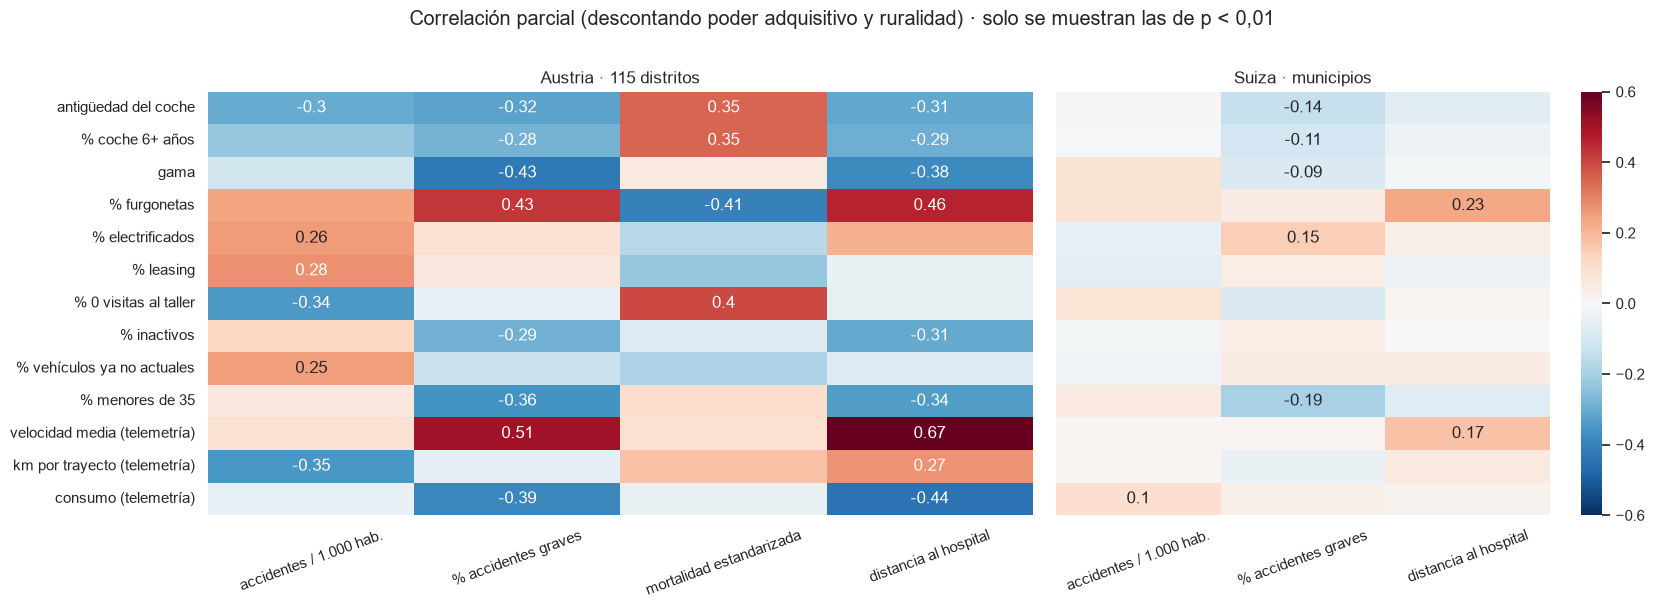

Suiza: 805 municipios · máxima |ρ parcial| = 0.23


In [35]:
def residuo(y, controles):
    """Parte de y (en rangos) que no explican los controles: base de la correlación parcial de Spearman."""
    X = np.column_stack([np.ones(len(y))] + [rankdata(c) for c in controles])
    yr = rankdata(y)
    return yr - X @ np.linalg.lstsq(X, yr, rcond=None)[0]

cli["coche_6_mas"] = cli["antiguedad_vehiculo"] >= 6
cli["sin_taller"] = cli["visitas_taller_por_vehiculo"].eq(0)
cli["vehiculos_pasados"] = df.groupby("client_id")["is_current_vehicle"].apply(lambda s: 1 - s.mean())
cli["menor_35"] = cli["age_range"].isin(["<25", "25-34"])
VARS_ZONA = {"antiguedad_vehiculo": "antigüedad del coche", "coche_6_mas": "% coche 6+ años", "gama_max": "gama",
             "pct_furgoneta": "% furgonetas", "pct_electrificado": "% electrificados", "leasing_activo": "% leasing",
             "sin_taller": "% 0 visitas al taller", "inactivo": "% inactivos", "vehiculos_pasados": "% vehículos ya no actuales",
             "menor_35": "% menores de 35", "speed_average": "velocidad media (telemetría)",
             "trip_distance_average": "km por trayecto (telemetría)", "fuel_consumption_average": "consumo (telemetría)"}
IND_ZONA = {"tasa_accidentes": "accidentes / 1.000 hab.", "pct_graves": "% accidentes graves",
            "mortalidad_std": "mortalidad estandarizada", "dist_hospital_km": "distancia al hospital"}

def correlaciones_zona(pais, min_clientes=30):
    s = cli[cli["country_code"] == pais].copy()
    s["pp_hab_pct"] = s["poder_adquisitivo_hab_eur"].rank(pct=True)
    g = s.groupby("zona")
    z = g[list(VARS_ZONA) + list(IND_ZONA) + ["pp_hab_pct"]].mean()
    z = z[g.size() >= min_clientes]
    filas = []
    for e in IND_ZONA:
        if z[e].notna().sum() < 20:
            continue
        for v in VARS_ZONA:
            controles = [c for c in ["pp_hab_pct", "dist_hospital_km"] if c != e]
            ok = z[list(dict.fromkeys([e, v, *controles]))].dropna()
            r, p = spearmanr(ok[e], ok[v])
            rp, pp_ = spearmanr(residuo(ok[e].values, [ok[c].values for c in controles]),
                                residuo(ok[v].values, [ok[c].values for c in controles]))
            filas.append({"indicador": IND_ZONA[e], "variable": VARS_ZONA[v], "ρ": r, "ρ parcial": rp, "p parcial": pp_, "zonas": len(ok)})
    return pd.DataFrame(filas)

corr_at, corr_ch = correlaciones_zona("AT"), correlaciones_zona("CH")
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [4, 3]})
for ax, (pais, t) in zip(axes, [("Austria · 115 distritos", corr_at), ("Suiza · municipios", corr_ch)]):
    mat = t.pivot(index="variable", columns="indicador", values="ρ parcial").reindex(index=list(VARS_ZONA.values()))
    sig = t.pivot(index="variable", columns="indicador", values="p parcial").reindex(index=list(VARS_ZONA.values())) < .01
    mat = mat[[c for c in IND_ZONA.values() if c in mat.columns]]
    sig = sig[mat.columns]
    sns.heatmap(mat, annot=mat.round(2).astype(str).where(sig, ""), fmt="", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6,
                ax=ax, cbar=ax is axes[1], yticklabels=ax is axes[0])
    ax.set(title=pais, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Correlación parcial (descontando poder adquisitivo y ruralidad) · solo se muestran las de p < 0,01", y=1.01)
plt.tight_layout()
plt.show()
print(f"Suiza: {corr_ch['zonas'].max()} municipios · máxima |ρ parcial| = {corr_ch['ρ parcial'].abs().max():.2f}")

#### a) La telemetría confirma los datos de accidentes

En los distritos austriacos con **más accidentes graves**, los clientes de Mercedes **conducen a más velocidad
media**: es la correlación más fuerte de todo el cruce y sobrevive al control. Es la mecánica conocida de la
siniestralidad: en carreteras secundarias rápidas los accidentes son menos, pero más graves. Que un dato **interno**
(la telemetría de nuestros clientes) cuadre con uno **externo** (las estadísticas oficiales) valida la unión por
código postal. La telemetría, que descartamos del modelo, tiene aquí un uso valioso.

In [36]:
t = cli[(cli["country_code"] == "AT") & cli["speed_average"].notna() & cli["pct_furgoneta"].eq(0) & cli["pct_electrificado"].eq(0)].copy()
t["cuartil_graves"] = pd.qcut(t["pct_graves"].rank(method="first"), 4, labels=["Q1 menos graves", "Q2", "Q3", "Q4 más graves"])
t.groupby("cuartil_graves", observed=True)[["speed_average", "trip_distance_average", "fuel_consumption_average", "dist_hospital_km"]].median().round(1)

,speed_average,trip_distance_average,fuel_consumption_average,dist_hospital_km
cuartil_graves,,,,
Q1 menos graves,43.30,13.90,7.10,0.00
Q2,49.40,13.50,6.80,4.00
Q3,52.80,13.40,6.70,8.60
Q4 más graves,55.30,14.10,6.50,11.50


Turismos de combustión de Austria: del cuartil de zonas con menos accidentes graves al de más, la velocidad media
sube de ~43 a ~55 km/h y el consumo **baja** (más carretera, menos atasco).

#### b) ¿Coches viejos en las zonas de más accidentes? Al revés

La hipótesis intuitiva (y el ejemplo de partida) era que en las zonas con más accidentes hay coches más viejos. Los
datos dicen **lo contrario**: en los distritos con más accidentes por habitante y más accidentes graves, los
clientes tienen coches **más nuevos**. Donde hay más accidentes por habitante hay además **más leasing** y **más
vehículos que ya no son actuales** (más rotación); el notebook Extra muestra también más 4MATIC y SUV.

In [37]:
foco = ["antigüedad del coche", "% coche 6+ años", "% leasing", "% vehículos ya no actuales", "% 0 visitas al taller", "% inactivos"]
corr_at[corr_at["variable"].isin(foco)].pivot(index="variable", columns="indicador", values="ρ parcial").reindex(foco).round(2)

indicador,% accidentes graves,accidentes / 1.000 hab.,distancia al hospital,mortalidad estandarizada
variable,,,,
antigüedad del coche,-0.32,-0.30,-0.31,0.35
% coche 6+ años,-0.28,-0.23,-0.29,0.35
% leasing,0.06,0.28,-0.04,-0.23
% vehículos ya no actuales,-0.13,0.25,-0.08,-0.18
% 0 visitas al taller,-0.05,-0.34,-0.04,0.40
% inactivos,-0.29,0.13,-0.31,-0.08


Dos lecturas no evidentes:
- Las zonas peligrosas **no** son de coches viejos: son zonas **rurales y de paso** donde el coche es imprescindible,
  se usa mucho y se renueva antes (y donde se escoge tracción total).
- **Más accidentes ↔ más vehículos que el cliente ya no tiene.** Encaja con coches que salen de la relación antes de
  tiempo (siniestros, cambios forzados). Hipótesis para Mercedes: un **programa de "después del siniestro"** (coche de
  sustitución, oferta de reposición, taller de carrocería oficial) para no perder al cliente en ese momento.

**El coche viejo sí aparece con la mortalidad**, no con los accidentes: ver c).

#### c) Distritos con más mortalidad, menos "mantenimiento preventivo"

En los distritos donde la población **muere antes** (mortalidad estandarizada por edad), los clientes tienen coches
**más viejos**, **más clientes que nunca pasan por el taller oficial** y **menos leasing**, también descontando
poder adquisitivo y ruralidad. Comprobación con coches de la misma edad:

In [38]:
m = cli[(cli["country_code"] == "AT") & cli["mortalidad_std"].notna()].copy()
m["cuartil_mortalidad"] = pd.qcut(m["mortalidad_std"].rank(method="first"), 4, labels=["Q1 baja", "Q2", "Q3", "Q4 alta"])
(m.pivot_table(index="cuartil_mortalidad", columns="banda_coche", values="sin_taller", aggfunc="mean", observed=True) * 100).round(1)

banda_coche,0-3,3-6,6-10,10+
cuartil_mortalidad,,,,
Q1 baja,35.00,28.90,56.10,64.00
Q2,37.00,31.90,57.10,65.10
Q3,37.10,33.00,61.80,70.10
Q4 alta,39.40,33.20,60.70,68.30


**Lectura (hipótesis):** la misma actitud que lleva a **cuidar la salud** con prevención (revisiones, chequeos)
parece llevar a **cuidar el coche** con mantenimiento oficial. La diferencia con coches de la misma edad es moderada
(unos 4-5 puntos) pero constante. Es una relación **entre zonas**, no prueba que cada cliente sea así. Para Mercedes:
en los distritos de alta mortalidad el mensaje de taller funciona mejor como **seguridad** ("revisión de frenos y
asistentes") que como mantenimiento.

#### d) Lejos del hospital: más fieles, más furgoneta, gama más baja

Los clientes de las zonas más alejadas del hospital tienen **menos inactivos**, **más furgonetas**, **gama más baja**,
trayectos más largos y **menos consumo**. El cliente rural depende de su coche y lo mantiene: es **más fiel**, pero
compra **utilidad** (furgoneta, 4MATIC), no prestigio.

#### e) Suiza: casi nada

En Suiza solo pasan el filtro relaciones **débiles** (|ρ| ≤ 0,23): más furgonetas y más velocidad lejos del
hospital, y coches algo más nuevos donde hay más accidentes graves. Es la **misma dirección que en Austria**, pero
mucho más débil. Motivos: la unidad es el
**municipio** (muy pequeño y ruidoso, frente a distritos austriacos de ~80.000 habitantes), las distancias son
cortas en casi todo el país y no hay mortalidad por zona. **No se fuerzan conclusiones donde no las hay.**

#### Resumen de 6.2

| Hallazgo | Tipo | Uso |
|---|---|---|
| Poder adquisitivo por hogar mide tamaño del hogar | **Problema de calidad** | El modelo usa el poder adquisitivo **por habitante** |
| Telemetría ↔ accidentes graves | Validación | Confirma que la unión por código postal es correcta |
| Zonas con más accidentes = coches más nuevos y más rotación | Rompe la intuición | Programa post-siniestro; 4MATIC |
| Mortalidad ↔ coches viejos y menos taller | Hipótesis | Mensajes de taller en clave de seguridad |
| Lejos del hospital = más fieles, más furgoneta | Perfil rural | Utilidad y fidelidad, no prestigio |

Los indicadores de zona **no entran en el modelo** (son datos de la zona, no del cliente; se justifica en el Reto 2)
pero sí se usan para **perfilar** los segmentos en el Reto 4.

### 6.3 Salud y ergonomía

Nuestro CSV no contiene ningún dato de salud, y no debe contenerlo (es un dato de categoría especial en el RGPD).
Pero sí tiene **edad** y **sexo** de cada cliente, y las estadísticas oficiales europeas publican la prevalencia de
problemas de salud **por país, edad y sexo**. Cruzando ambas cosas se obtiene, para cada cliente, la **probabilidad
esperada** de tener un problema de salud que afecta a la conducción y al uso del coche.

| Indicador | Fuente oficial | Países | Por qué importa en un coche |
|---|---|---|---|
| Limitación (moderada o grave) en las actividades habituales por salud | Eurostat, EU-SILC 2023 (`hlth_silc_06`) | AT y CH | Subir, bajar, cargar, girarse: la ergonomía general |
| Limitación grave | ídem | AT y CH | Necesidad de adaptaciones |
| Problema lumbar crónico | Eurostat, Encuesta Europea de Salud EHIS 2019 (`hlth_ehis_cd1e`) | AT | Horas sentado, vibraciones, asiento |
| Problema cervical crónico | ídem | AT | Girar la cabeza para maniobrar y mirar el ángulo muerto |
| Artrosis | ídem | AT | Rodillas, caderas y manos: entrar, salir, abrir, cargar |

Suiza no participa en la encuesta EHIS, así que los problemas lumbares, cervicales y la artrosis solo se estiman para
los clientes austriacos. La tabla descargada se guarda en `datos_salud_edad_sexo.csv`.

**Fuentes:** Eurostat, dataset `hlth_silc_06` (EU-SILC 2023) y dataset `hlth_ehis_cd1e` (EHIS 2019), descargados de la
API oficial de Eurostat. Enlaces exactos y condiciones de uso en
[`Fuentes_Datos_Externos.md`](Fuentes_Datos_Externos.md).

⚠️ **Lo que esto es y lo que no es.** Es una probabilidad **esperada** según edad, sexo y país: no sabemos si un
cliente concreto tiene dolor de espalda. Sirve para estimar **cuántos** clientes de un grupo probablemente lo tienen y
para decidir **qué equipamiento ofrecer**, nunca para etiquetar a una persona.

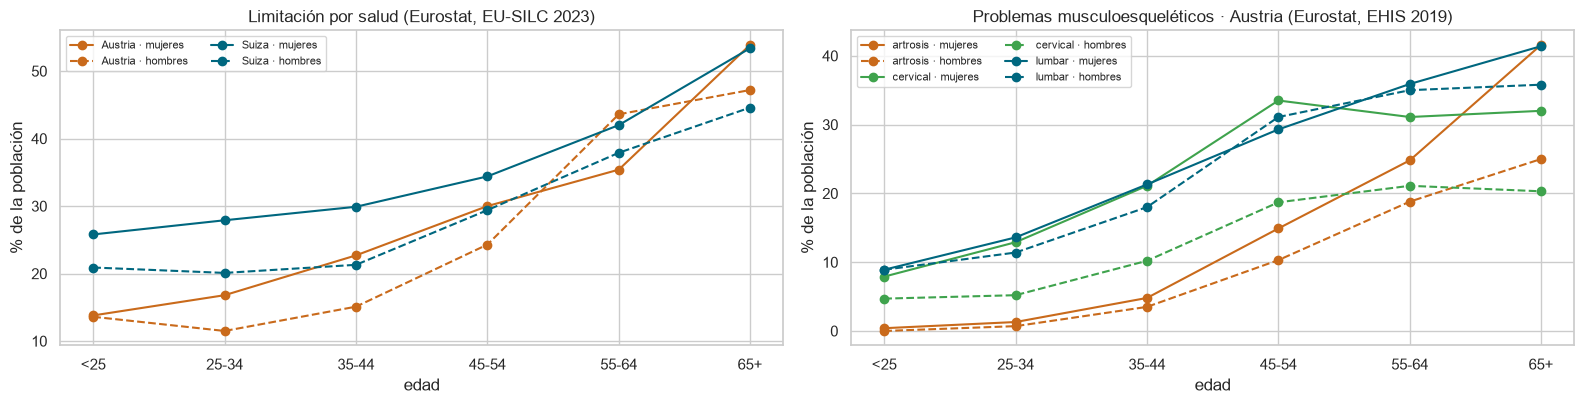

In [39]:
# Tabla descargada de Eurostat al inicio del apartado 6 (construir_tabla_salud en features.py)
salud = pd.read_csv("datos_salud_edad_sexo.csv")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
PAIS = {"AT": "Austria", "CH": "Suiza"}
SEXO = {"female": "mujeres", "male": "hombres"}
IND = {"p_lumbar": "lumbar", "p_cervical": "cervical", "p_artrosis": "artrosis"}
estilo = {"female": "-", "male": "--"}
for (pais, sexo), g in salud[(salud["indicador"] == "p_limitacion") & (salud["gender_derived"] != "unknown")].groupby(["country_code", "gender_derived"]):
    g = g.set_index("age_range").reindex(ORDEN_EDAD)
    axes[0].plot(ORDEN_EDAD, g["prevalencia"] * 100, marker="o", ls=estilo[sexo], color={"AT": "#c96a1b", "CH": AZUL}[pais],
                 label=f"{PAIS[pais]} · {SEXO[sexo]}")
axes[0].set(title="Limitación por salud (Eurostat, EU-SILC 2023)", xlabel="edad", ylabel="% de la población")
for (ind, sexo), g in salud[salud["indicador"].isin(IND) & (salud["gender_derived"] != "unknown")].groupby(["indicador", "gender_derived"]):
    g = g.set_index("age_range").reindex(ORDEN_EDAD)
    axes[1].plot(ORDEN_EDAD, g["prevalencia"] * 100, marker="o", ls=estilo[sexo],
                 color={"p_lumbar": AZUL, "p_cervical": "#3fa34d", "p_artrosis": "#c96a1b"}[ind], label=f"{IND[ind]} · {SEXO[sexo]}")
axes[1].set(title="Problemas musculoesqueléticos · Austria (Eurostat, EHIS 2019)", xlabel="edad", ylabel="% de la población")
for ax in axes:
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [40]:
esperados = pd.DataFrame({
    "clientes con dato": cli[COLS_SALUD].notna().sum(),
    "% esperado": cli[COLS_SALUD].mean() * 100,
    "clientes afectados (esperados)": cli[COLS_SALUD].sum(),
}).rename(index={"p_limitacion": "limitación por salud", "p_limitacion_grave": "limitación grave", "p_lumbar": "lumbar (AT)",
                 "p_cervical": "cervical (AT)", "p_artrosis": "artrosis (AT)"})
esperados.round(1)

,clientes con dato,% esperado,clientes afectados (esperados)
limitación por salud,173456,31.60,"54,826.50"
limitación grave,173456,6.90,"12,012.80"
lumbar (AT),58693,27.20,"15,965.10"
cervical (AT),58693,18.20,"10,697.00"
artrosis (AT),58693,13.80,"8,109.30"


Se esperan unos **55.000 clientes con alguna limitación por salud** (casi 1 de cada 3) y, solo en Austria, unos
16.000 con problema lumbar, 11.000 cervical y 8.000 con artrosis. Para un fabricante de coches, la salud musculoesquelética
de su base de clientes **no es un tema menor**: afecta a cómo se entra, se sale, se maniobra y se aguanta un trayecto.

#### a) La brecha ergonómica

Un coche de **posición alta** (SUV, monovolumen, furgoneta) se entra y se sale sin agacharse y con menos esfuerzo de
rodillas y caderas. Si la necesidad ergonómica guiase la compra, la proporción de coches altos debería subir con la
edad, igual que sube la limitación por salud. ¿Lo hace?

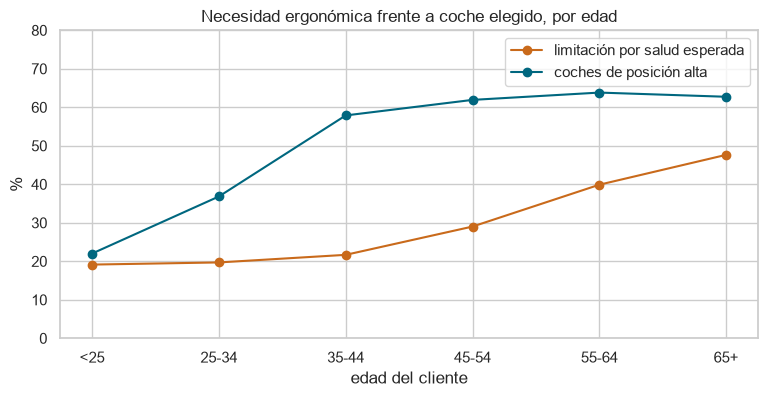

clientes con limitación esperada que conducen un coche que no es alto   21,446.00
clientes de 65+ sin ningún coche alto                                   12,409.00
  de ellos, con limitación esperada                                      5,932.00
dtype: float64

In [41]:
por_edad = cli.groupby("age_range").agg(limitacion=("p_limitacion", "mean"), posicion_alta=("pct_posicion_alta", "mean"),
                                        clientes=("p_limitacion", "size")).reindex(ORDEN_EDAD)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ORDEN_EDAD, por_edad["limitacion"] * 100, marker="o", color="#c96a1b", label="limitación por salud esperada")
ax.plot(ORDEN_EDAD, por_edad["posicion_alta"] * 100, marker="o", color=AZUL, label="coches de posición alta")
ax.set(title="Necesidad ergonómica frente a coche elegido, por edad", xlabel="edad del cliente", ylabel="%", ylim=(0, 80))
ax.legend()
plt.show()
cli["coche_no_alto"] = cli["pct_posicion_alta"].eq(0)
brecha = cli["age_range"].eq("65+") & cli["coche_no_alto"]
pd.Series({
    "clientes con limitación esperada que conducen un coche que no es alto": (cli["p_limitacion"] * cli["coche_no_alto"]).sum(),
    "clientes de 65+ sin ningún coche alto": brecha.sum(),
    "  de ellos, con limitación esperada": cli.loc[brecha, "p_limitacion"].sum(),
}).round(0)

**Lectura:** la limitación por salud **se duplica** entre los 35-44 y los 65+ (del ~22 % al ~48 %), pero la proporción
de coches altos **se estanca** en ~63 % a partir de los 45 años. La elección de coche **no acompaña** a la necesidad
ergonómica: ~12.400 clientes de 65+ no tienen ningún coche alto, y unos 5.900 de ellos probablemente tienen una
limitación por salud. Es una **brecha ergonómica**: un público concreto para un cambio a un **SUV compacto o
monovolumen** (GLA, GLB, Clase B, EQA/EQB) con el argumento de la **comodidad**, no de la edad.

Las mujeres de 65+ son las que más coches altos tienen (67,5 % frente a 64,8 % de los hombres), y son también las que
más artrosis y problemas cervicales declaran (ver gráfico): una señal, pequeña, de que la necesidad sí pesa cuando se
percibe.

In [42]:
cli.pivot_table(index="age_range", columns="gender_derived", values="pct_posicion_alta", aggfunc="mean").reindex(ORDEN_EDAD).mul(100).round(1)

gender_derived,female,male,unknown
age_range,,,
<25,16.90,23.50,22.80
25-34,34.00,38.60,34.90
35-44,58.60,58.00,56.20
45-54,63.80,62.00,57.90
55-64,65.20,63.40,64.80
65+,67.50,64.80,56.10


#### b) Tiempo al volante (telemetría)

Pasar mucho tiempo sentado y expuesto a vibraciones es un factor de riesgo de dolor lumbar conocido en salud laboral.
La telemetría permite estimar la **duración media de un trayecto** (distancia media / velocidad media). Detalle de
calidad: hay ~1.800 relaciones con velocidad media < 5 km/h que darían trayectos de días; se descartan, igual que las
duraciones medias de más de 4 horas.

In [43]:
# % sobre los clientes con telemetría (sin ella no se sabe la duración)
cli["trayecto_largo"] = cli["minutos_trayecto"].ge(30).where(cli["minutos_trayecto"].notna())
cli["tipo_coche"] = np.select([cli["pct_furgoneta"] > .5, cli["pct_posicion_alta"] > .5], ["furgoneta", "SUV / monovolumen"], "turismo bajo o medio")
display(cli.groupby("tipo_coche")["minutos_trayecto"].describe(percentiles=[.5, .9])[["count", "50%", "90%"]].round(1))
cli.groupby("age_range").agg(minutos_mediana=("minutos_trayecto", "median"), pct_trayectos_30min=("trayecto_largo", "mean")).reindex(ORDEN_EDAD).assign(
    pct_trayectos_30min=lambda t: t["pct_trayectos_30min"] * 100).round(1)

,count,50%,90%
tipo_coche,,,
SUV / monovolumen,"33,757.00",17.20,26.30
furgoneta,"8,152.00",19.80,36.20
turismo bajo o medio,"34,388.00",17.80,27.10


,minutos_mediana,pct_trayectos_30min
age_range,,
<25,18.60,4.60
25-34,18.10,5.76
35-44,17.60,6.49
45-54,17.90,7.14
55-64,17.70,7.99
65+,16.50,7.37


**Lectura:** el trayecto típico dura ~18 minutos y solo ~7 % de los clientes con telemetría tiene trayectos medios de
30 minutos o más.
Los **conductores de furgoneta** hacen los trayectos más largos: es el grupo con más exposición a estar sentado, y en
su caso el asiento es una herramienta de trabajo. Los clientes de 65+ hacen los trayectos **más cortos**: para ellos
la ergonomía que importa es la de **entrar, salir y maniobrar**, no la de aguantar horas.

#### c) De cada problema de salud a un equipamiento Mercedes-Benz

| Problema (fuente oficial) | Qué le cuesta al conductor | Equipamiento Mercedes-Benz que lo alivia |
|---|---|---|
| Limitación general por salud | Entrar, salir, cargar | Posición alta (GLA, GLB, Clase B, EQA/EQB), KEYLESS-GO, portón trasero eléctrico EASY-PACK, Clase V con puertas correderas |
| Problema lumbar | Trayectos largos, vibraciones | Asientos multicontorno con masaje, apoyo lumbar de 4 vías, ENERGIZING Comfort, suspensión AIRMATIC |
| Problema cervical | Girar la cabeza al maniobrar o cambiar de carril | Cámara de 360°, Asistente de ángulo muerto, Active Parking Assist, Head-up Display |
| Artrosis (rodillas, caderas, manos) | Agacharse, fuerza en las manos, frío | Posición alta, KEYLESS-GO, cierre de confort de puertas, volante y asientos calefactables |
| Limitación grave | Conducir un coche de serie | Adaptaciones de conducción con transformadores homologados; Clase V adaptada |

**Uso responsable:** el mensaje es siempre de **comodidad** ("entra y sal sin esfuerzo", "llega descansado"), nunca de
salud ni de edad. El dato de salud es una estimación estadística: decide **qué equipamiento destacar**, no a quién se le
atribuye un problema.

## 7. Resumen de hallazgos

### ¿Cómo son los clientes?
- **173.456 clientes** de **Suiza (66 %)** y **Austria (34 %)**, con 302.850 relaciones con 244.519 vehículos.
- Perfil **maduro**: el 61 % tiene 45 años o más; los menores de 25 son menos del 5 %.
- Mayoría **masculina** (65 % hombre, 18 % mujer, 17 % sin dato; el género es inferido).
- Relación **reciente**: mediana de 36 meses como cliente, con un pico artificial en 36.
- Casi todos tienen **un vehículo conectado**. El 10 % no tiene ninguno: clientes **inactivos**.
- El 27 % ha tenido más de un Mercedes; ~1.700 clientes (1 %) tienen perfil de **flota** y acumulan el 20 % de las filas.
- Casi todo es **particular (B2C)**: el B2B es solo el 1,8 % de las relaciones.
- **Leasing**: el 29 % lo ha usado alguna vez, mucho más en Suiza.
- **Gama**: dominan los **turismos** (84 %), con GLC, C, A y E-Class a la cabeza. **1 de cada 4** vehículos con motor
  conocido es **electrificado**, más en Austria.
- El **email** está consentido por el 98 %: no diferencia. Teléfono y correo postal sí.

### Problemas de calidad y solución
| Problema | Solución |
|---|---|
| Granularidad cliente–vehículo y vehículos compartidos | Agregar a 1 fila por cliente; telemetría y taller como datos de la relación |
| Telemetría ausente de forma **estructural** (BEV, no propietarios, coches antiguos) | No imputar ni modelar; solo perfilar con advertencia |
| Motorización nula por sistema de origen | Deducción por nombre comercial + `UNKNOWN` |
| Género nulo concentrado en jóvenes y mayores | Categoría `unknown`; fuera del modelo |
| Socioeconómicos nulos y distintos por país | Mediana del país; variable relativa al país |
| Eliminar filas con nulos | Descartado: perdería el 18,6 % de clientes y sesgaría edad y país |
| Medianas/modas discretizadas y topes del sistema | Excluir medianas/modas; describir con medianas de las medias |
| Visitas al taller registradas distinto por país y ligadas a la garantía | Relativo al país; interpretar con la antigüedad del coche |
| Pico de 36 meses, CP mal formados, desajustes menores | Documentados; impacto acotado |
| Identificadores, metadatos y variables redundantes | Excluidos (apartado 2) |
| Poder adquisitivo **por hogar** inflado en zonas rurales (hogares más grandes) | Usar el **por habitante** (6.2) |
| Códigos postales válidos en formato pero inexistentes (`0000`, `9999`…) | Sin dato de zona; no se inventa |

 Relaciones no evidentes (apartado 6)
| Hallazgo | Implicación para Mercedes-Benz |
|---|---|
| El cliente de 65+ tiene el doble de coches de 10+ años, pero los usa mucho menos | Coche antiguo con pocos km: recompra atractiva y cambio a un coche más seguro, no más caro |
| 1 de cada 7 híbridos enchufables consume como un combustión | No se cargan: wallbox, carga y paso a 100 % eléctrico |
| En hogares con varios coches, el electrificado es el más nuevo y de más gama | La electrificación sustituye al coche principal; siguiente paso, el segundo coche |
| 0 visitas al taller → hasta 4 veces más clientes inactivos, con coches de la misma edad | El taller es un indicador temprano de abandono |
| Los consentimientos no predicen el abandono | No confundir "no contactable" con "a punto de irse" |
| Los AMG no se conducen más rápido | El AMG se vende como imagen y experiencia |
| Zonas con más accidentes: coches más nuevos y más rotación (no más viejos) | Programa post-siniestro, 4MATIC |
| Telemetría ↔ accidentes graves | Valida la unión con datos externos |
| Distritos con más mortalidad: coches más viejos y menos taller oficial | Taller en clave de seguridad |
| Limitación por salud esperada: del ~22 % (35-44) al ~48 % (65+), pero los coches altos se estancan en ~63 % | Brecha ergonómica: ~12.400 clientes de 65+ sin coche alto; SUV compacto o monovolumen por comodidad |
| Conductores de furgoneta: los trayectos más largos | Asientos de confort como herramienta de trabajo |

In [44]:
resumen = {
    "clientes": n_clients,
    "relaciones cliente-vehículo": n_rows,
    "vehículos": n_vehicles,
    "% clientes CH": (clientes["country_code"] == "CH").mean() * 100,
    "% clientes hombres (inferido)": (clientes["gender_derived"] == "male").mean() * 100,
    "% clientes 45+": clientes["age_range"].isin(["45-54", "55-64", "65+"]).mean() * 100,
    "% clientes con >1 vehículo": (veh_por_cliente > 1).mean() * 100,
    "% clientes con financiación/leasing alguna vez": (clientes["finance_leasing_status"] != "never_active").mean() * 100,
    "% relaciones B2B": (df["role_type"] == "B2B").mean() * 100,
    "% vehículos electrificados (sobre motor conocido)": df["engine_concept"].isin(["PLUGIN_HYBRID", "ELECTRIC"]).sum() / df["engine_concept"].notna().sum() * 100,
    "% clientes sin vehículo conectado": (clientes["currently_connected_vehicles"] == 0).mean() * 100,
    "% clientes con consentimiento email": clientes["consent_epost_communication_channel"].mean() * 100,
    "% clientes que se perderían eliminando nulos": perdida * 100,
}
pd.Series(resumen).round(1)

clientes                                            173,456.00
relaciones cliente-vehículo                         302,850.00
vehículos                                           244,519.00
% clientes CH                                            66.20
% clientes hombres (inferido)                            65.00
% clientes 45+                                           60.80
% clientes con >1 vehículo                               26.70
% clientes con financiación/leasing alguna vez           29.40
% relaciones B2B                                          1.80
% vehículos electrificados (sobre motor conocido)        25.10
% clientes sin vehículo conectado                        10.40
% clientes con consentimiento email                      98.30
% clientes que se perderían eliminando nulos             18.60
dtype: float64